<div style="background:#0B1020;border-left:6px solid #A78BFA;padding:30px;border-radius:12px;font-family:Segoe UI,Arial,sans-serif;">
<p style="color:#22D3EE;font-size:12px;letter-spacing:2px;font-weight:700;">EUROVISION · 1998-2012 · PRÉPARATION & ANALYSE</p>
<h1 style="color:#F4F5FC;font-size:34px;margin:12px 0;">La musique en données</h1>
<p style="color:#C4CDE0;font-size:16px;">Des données traçables pour un tableau de bord qui raconte juste.</p>
<p style="color:#A78BFA;">Abdoulaye KONE · Projet de portfolio en collaboration</p>
</div>

**Question étudiée : comment évoluent la participation et les résultats de l’Eurovision, et que permettent réellement d’observer les caractéristiques musicales disponibles ?**

Ce carnet reprend la progression pédagogique du notebook *Qualité de vie* : sources, diagnostic, décisions motivées, figures commentées, exports et contrôles. Les méthodes sont adaptées à l’Eurovision : pas d’imputation des caractéristiques musicales, pas de suppression des passages répétés et pas de score composite de « qualité » inventé.

**Parcours de lecture**

1. [Cadrer le projet](#etape-1) · [Sources et environnement](#etape-2) · [Dictionnaire et granularité](#etape-3)
2. [Diagnostiquer](#etape-4) · [Harmoniser les textes](#etape-5) · [Convertir les types](#etape-6)
3. [Comprendre les absences](#etape-7) · [Contrôler les valeurs](#etape-8) · [Rapprocher les résultats](#etape-9)
4. [Construire les tables](#etape-10) · [Explorer sans surinterpréter](#etape-11) · [Exporter et vérifier](#etape-12)

**Reproduction.** Ouvrir ce notebook à la racine du dépôt, puis choisir **Redémarrer le noyau et tout exécuter**. Il utilise `pandas`, `numpy`, `openpyxl`, `matplotlib`, `scipy` et `IPython` ; `nbformat`, `nbclient` et `ipykernel` permettent aussi l’exécution automatisée. Les versions effectivement utilisées sont affichées ci-dessous. Aucun appel réseau n’est nécessaire : les références de correction vérifiées sont intégrées dans le carnet. Les sorties sont régénérées dans `data/processed/`, `reports/` et `assets/analysis/`.

<a id="etape-1"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">01 · Cadrer le projet</h2>


Le périmètre est **1998-2012**, demi-finales et finales présentes dans le classeur local. Une **participation** correspond à un pays et une édition ; un **passage** correspond à une participation dans une étape. Les votes détaillés concernent uniquement les finales.

| Décision | Pourquoi |
|---|---|
| Préserver les classeurs d’entrée | Pouvoir revenir à chaque valeur d’origine |
| Séparer participations, passages et votes | Éviter les doubles comptes et les multiplications de lignes |
| Garder les absences acoustiques | Ne pas fabriquer une chanson « moyenne » ou un lien artificiel avec les résultats |
| Corriger seulement les faits vérifiés | Une cohérence interne ne prouve pas l’exactitude historique |
| Afficher les dénominateurs | Une moyenne musicale ne porte pas sur toutes les chansons |

Le traitement prépare de nouvelles tables. Le branchement de ces sorties dans Power BI fera l’objet d’une étape distincte. Les portraits sont contrôlés dans la section 10.1 : association documentée par pays-édition, licence, empreinte et dimensions de chaque fichier. Aucune reconnaissance faciale n’est utilisée.

In [1]:
from pathlib import Path
import sys, json, hashlib, unicodedata, re, html, platform, importlib.metadata, io, base64
import urllib.request
from PIL import Image
from xml.etree import ElementTree
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter, MaxNLocator
from scipy.stats import spearmanr
from IPython.display import display, HTML, Markdown
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.worksheet.table import Table, TableStyleInfo

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/source/eurovision_1998 to 2012.xlsx').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Ouvrir le notebook dans le dépôt contenant data/source/.')
SOURCE = ROOT / 'data/source/eurovision_1998 to 2012.xlsx'
WORKING = ROOT / 'data/working/fichier_avec_images.xlsx'
IMAGE_CATALOGUE = ROOT / 'assets/artists/catalogue_images.csv'
PROCESSED, REPORTS, FIGURES = [ROOT / p for p in ['data/processed', 'reports', 'assets/analysis']]
for folder in [PROCESSED, REPORTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
VERIFY_DATE = '2026-10-19'
C = dict(bg='#0B1020', panel='#171F35', text='#F4F5FC', muted='#B5BED3',
         violet='#A78BFA', cyan='#22D3EE', amber='#FBBF77', grid='#303A54')
plt.rcParams.update({'figure.facecolor':C['bg'], 'axes.facecolor':C['panel'],
    'text.color':C['text'], 'axes.labelcolor':C['muted'], 'xtick.color':C['muted'],
    'ytick.color':C['muted'], 'axes.edgecolor':C['grid'], 'grid.color':C['grid'],
    'font.family':'DejaVu Sans', 'font.size':10, 'axes.titleweight':'bold',
    'axes.spines.top':False, 'axes.spines.right':False, 'figure.dpi':110,
    'savefig.facecolor':C['bg'], 'axes.titlepad':16})

**Conventions de lecture.** Les fonctions ci-dessous centralisent les tableaux, figures, journaux et contrôles. Toutes sont définies dans ce notebook.

In [2]:
journal, controls, figure_paths = [], [], []
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
def fr(value, digits=0):
    return f'{value:,.{digits}f}'.replace(',', '\u202f').replace('.', ',')
def table(df, caption=None, limit=30):
    show = df.head(limit)
    styler = show.style.hide(axis='index').format(na_rep='-', precision=3, decimal=',', thousands=' ').set_properties(**{
        'text-align':'left', 'padding':'8px 12px', 'border-bottom':'1px solid #E2E8F0',
        'color':'#18243A', 'background-color':'#F8FAFC'}).set_table_styles([
        {'selector':'th','props':[('background','#171F35'),('color','#FFFFFF'),('padding','10px 12px'),('text-align','left')]},
        {'selector':'caption','props':[('color','#7C3AED'),('font-weight','bold'),('text-align','left'),('padding','12px 0')]}])
    if caption: styler = styler.set_caption(caption)
    display(styler)
    if len(df)>limit: display(Markdown(f'*{len(show)} lignes affichées sur {len(df)} ; le rapport exporté contient le détail.*'))
def lecture(text):
    display(HTML('<div style="border-left:4px solid #22D3EE;background:#F0F9FF;padding:14px 18px;color:#18243A;margin:12px 0;">'
                 '<strong>Lecture</strong> · '+html.escape(text)+'</div>'))
def log_change(table_name, row_id, field, before, after, rule, reason, url=''):
    def serial(x):
        if pd.isna(x): return '<manquant>'
        return str(x)
    if serial(before)!=serial(after):
        journal.append(dict(table=table_name, ligne=str(row_id), variable=field,
            avant=serial(before), apres=serial(after), regle=rule, justification=reason, reference=url))
def check(name, condition, detail='', warning=False):
    controls.append(dict(controle=name, statut='OK' if condition else ('À examiner' if warning else 'ÉCHEC'), detail=str(detail)))
    if not condition and not warning: raise AssertionError(f'{name} : {detail}')
def save_figure(fig, name, subtitle):
    fig.text(.015,.015,subtitle,fontsize=8,color=C['muted'])
    fig.tight_layout(rect=(0,.055,1,1))
    path = FIGURES / f'{name}.png'
    fig.savefig(path,dpi=180,bbox_inches='tight')
    figure_paths.append(path)
    display(fig)
    plt.close(fig)

<a id="etape-2"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">02 · Sources, environnement et empreintes</h2>


La source principale est le classeur local `eurovision_1998 to 2012.xlsx`. Sa feuille `Performance` contient un dictionnaire, mais **l’auteur amont, la version de collecte et la licence du jeu enrichi ne sont pas renseignés dans ce fichier**. Les caractéristiques musicales y sont attribuées à *Echonest*. Cette attribution ne permet pas d’identifier l’enregistrement audio analysé.

`fichier_avec_images.xlsx` est une copie de travail inspectée pour comparaison, pas une deuxième source historique indépendante. Les anciennes URL d’images ne prouvent ni l’identité du portrait ni ses droits de réutilisation. Un catalogue documenté et les crédits des nouveaux visuels sont ajoutés dans la section 10.1. Les références officielles mobilisées pour les corrections sont listées à l’étape 9.

In [3]:
input_paths = [SOURCE] + ([WORKING] if WORKING.is_file() else []) + [IMAGE_CATALOGUE]
hashes_before = {str(p.relative_to(ROOT)):sha256(p) for p in input_paths}
versions = {'Python':platform.python_version()}
for package in ['pandas','numpy','openpyxl','matplotlib','scipy','ipython','nbformat','nbclient','ipykernel','Pillow']:
    versions[package] = importlib.metadata.version(package)
table(pd.DataFrame(versions.items(),columns=['Composant','Version']), 'Environnement de cette exécution')
table(pd.DataFrame([{'Fichier':p, 'SHA-256':h} for p,h in hashes_before.items()]), 'Identité des sources')
# Ne pas laisser pandas interpréter « NA » dès la lecture : on veut d’abord diagnostiquer ces codes.
sheets = pd.read_excel(SOURCE,sheet_name=None,keep_default_na=False)
raw = sheets['eurovision_meta'].copy(deep=True)
raw_votes = sheets['Voting Final'].copy(deep=True)
source_dictionary = sheets['Performance'].copy(deep=True)
raw_work = pd.read_excel(WORKING,keep_default_na=False) if WORKING.is_file() else None
table(pd.DataFrame([{'Feuille':k,'Lignes':len(v),'Colonnes':len(v.columns)} for k,v in sheets.items()]), 'Le classeur d’origine')

Composant,Version
Python,3.12.0
pandas,3.0.5
numpy,2.5.3
openpyxl,3.1.5
matplotlib,3.11.2
scipy,1.18.1
ipython,9.17.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0


Fichier,SHA-256
data\source\eurovision_1998 to 2012.xlsx,e29be6e7825aa1e04c87bc4e1b7d86a39511c20795221c01b1473b91ea86e2d6
data\working\fichier_avec_images.xlsx,618f6a75447cc1bb6a263a6b4457ac3cbfdccc47156b37792e3b0e275a71ba2a
assets\artists\catalogue_images.csv,9e74ca50c03d3522e629ab5c1f41efa9eee28aabf47a70a400d6bc8ab4ba69a9


Feuille,Lignes,Colonnes
eurovision_meta,648,31
Voting Final,12 131,4
Performance,31,3


<a id="etape-3"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">03 · Dictionnaire et unité d’observation</h2>


| Table de sortie | Une ligne représente | Clé |
|---|---|---|
| `editions` | Une année | `edition` |
| `pays` | Une entité historique du jeu | `pays_id` |
| `participations` | Un pays dans une édition | `participation_id` |
| `resultats_etapes` | Un passage en finale ou demi-finale | `resultat_id` |
| `votes_finale` | Un vote d’un donneur vers un finaliste, même nul | `vote_id` |

La Serbie-et-Monténégro est conservée séparément de la Serbie et du Monténégro. Les identifiants `C001…` sont des clés internes, pas des codes ISO. Le champ `Region` est un **regroupement de la source** ; il ne constitue pas une classification géographique officielle.

Les champs `Song.Quality` (qualité estimée, méthode inconnue) et `Happiness` (mots de paroles, lexique labMT selon le dictionnaire) sont conservés pour traçabilité, mais exclus des conclusions centrales. La durée garde son unité **non documentée** : aucune conversion en secondes ou minutes n’est supposée.

In [4]:
table(source_dictionary.rename(columns={'Column name':'Variable source','Type':'Type annoncé','Description':'Description du classeur'}), 'Dictionnaire fourni',limit=40)
AUDIO = ['energy','duration','acousticness','danceability','tempo','speechiness','key',
         'liveness','time_signature','mode','loudness','valence']
PROFILE = ['energy','danceability','acousticness']
BOUNDED = ['energy','acousticness','danceability','speechiness','liveness','valence']
INT_FIELDS = ['Sr.No','Year','Place','Points','Is.Final','Semi.Final.Number','Song.In.English','key','time_signature','mode']
FLOAT_FIELDS = [x for x in AUDIO if x not in INT_FIELDS]+['Song.Quality','Normalized.Points','Happiness']
TEXT_FIELDS = [c for c in raw if c not in INT_FIELDS+FLOAT_FIELDS]
LABELS = {'energy':'Énergie','danceability':'Dansabilité','acousticness':'Acousticité',
          'tempo':'Tempo','duration':'Durée · unité source','speechiness':'Parole',
          'liveness':'Présence du public','valence':'Valence','loudness':'Niveau sonore',
          'key':'Tonalité','mode':'Mode','time_signature':'Mesure','Happiness':'Lexique des paroles',
          'Artist.gender':'Genre déclaré','Group.Solo':'Formation déclarée'}

Variable source,Type annoncé,Description du classeur
Year,Number,The year of the entry
Country,String,Country of the performer
Region,String,Region of the performer
Artist,String,Name of artist
Song,String,Title of song
Artist.gender,String,"Male, female or both"
Group.Solo,String,Group or solo
Place,Number,Placement in competition
Points,Number,Total number of points
Home.Away.Country,String,If the country is hosting


<a id="etape-4"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">04 · Diagnostic brut, avant toute correction</h2>


Les doublons sont examinés à trois niveaux : ligne identique, pays-année, puis pays-année-étape. Le deuxième niveau met en évidence les passages successifs d’une même participation et ne justifie aucune suppression.

Les lignes Excel sont numérotées dès l’import pour retrouver une observation même lorsque `Sr.No` manque. Les zéros sont comptés séparément des codes d’absence.

In [5]:
def missing_token(value, category=False):
    if pd.isna(value): return True
    text = str(value).strip().casefold()
    return text in ({'', 'na', 'n/a', 'nan', 'null'} | ({'non spécifié'} if category else set()))
raw_missing = pd.DataFrame({c:raw[c].map(lambda x:missing_token(x, category=True)) for c in raw})
missing_report = pd.DataFrame({'Variable':raw.columns, 'Absences brutes':raw_missing.sum().values,
    'Taux (%)':raw_missing.mean().values*100, 'Zéros réels':[(raw[c].astype(str).isin(['0','0.0'])).sum() for c in raw]})
raw_stage = raw.assign(_semi=raw['Semi.Final.Number'].map(lambda x:'F' if missing_token(x) else f'SF{int(x)}'))
raw_diagnostic = pd.DataFrame([
    ['Lignes identiques',int(raw.duplicated().sum()),'Aucune suppression automatique'],
    ['Répétitions pays-année',int(raw.duplicated(['Year','Country']).sum()),'Passages à conserver'],
    ['Répétitions pays-année-étape',int(raw_stage.duplicated(['Year','Country','_semi']).sum()),'Clé métier des passages'],
    ['Identifiants Sr.No absents',int(raw_missing['Sr.No'].sum()),'Utiliser une clé métier et la ligne Excel'],
    ['Participations distinctes',raw[['Year','Country']].drop_duplicates().shape[0],'Grain des participations']
],columns=['Contrôle brut','Nombre','Décision'])
table(raw_diagnostic,'Ce qui est un doublon… et ce qui ne l’est pas')
table(missing_report.sort_values('Taux (%)',ascending=False),'Absences et zéros avant traitement',limit=35)

Contrôle brut,Nombre,Décision
Lignes identiques,0,Aucune suppression automatique
Répétitions pays-année,140,Passages à conserver
Répétitions pays-année-étape,0,Clé métier des passages
Identifiants Sr.No absents,1,Utiliser une clé métier et la ligne Excel
Participations distinctes,508,Grain des participations


Variable,Absences brutes,Taux (%),Zéros réels
Artist.gender,422,"65,123",0
Group.Solo,422,"65,123",0
Semi.Final.Number,367,"56,636",0
Happiness,344,"53,086",0
acousticness,168,"25,926",0
valence,168,"25,926",0
liveness,166,"25,617",0
energy,166,"25,617",0
danceability,166,"25,617",0
speechiness,166,"25,617",0


**Comparer la copie de travail.** La jointure repose sur la clé métier du passage, jamais sur le seul numéro de ligne.

In [6]:
if raw_work is not None:
    left=raw.copy();right=raw_work.copy()
    for frame in [left,right]:
        frame['_semi']=frame['Semi.Final.Number'].map(lambda x:'F' if missing_token(x) else f'SF{int(x)}')
    comparison=left.merge(right,on=['Year','Country','_semi'],how='outer',validate='one_to_one',indicator=True,suffixes=('_source','_travail'))
    check('Copie de travail : mêmes clés de passage',comparison['_merge'].eq('both').all())
    disagreements=[]
    for col in raw.columns.difference(['Year','Country']):
        a=comparison[col+'_source'].map(lambda x:None if missing_token(x,True) else str(x).strip())
        b=comparison[col+'_travail'].map(lambda x:None if missing_token(x,True) else str(x).strip())
        diff=~((a==b)|(a.isna()&b.isna()))
        if diff.any(): disagreements.append({'Variable':col,'Écarts hors codes d’absence':int(diff.sum())})
    check('Copie de travail : données hors codes d’absence identiques',not disagreements,str(disagreements))
    lecture('La copie de travail possède les mêmes passages et les mêmes valeurs utiles après reconnaissance des codes d’absence. Elle n’ajoute pas de preuve indépendante ni de couverture d’images.')

<a id="etape-5"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">05 · Harmoniser les textes sans réécrire l’histoire</h2>


Les espaces en début et fin, les espaces multiples et la normalisation Unicode NFC sont traités de manière déterministe. Les accents et la casse des noms sont préservés. Aucun rapprochement approximatif n’est utilisé.

L’alias `Bosnia-Herzegovina` des votes est aligné explicitement sur `Bosnia and Herzegovina`. Les libellés d’artistes et de chansons confirmés sur les pages officielles sont corrigés à l’étape 9. Les variantes restantes et les glyphes suspects sont exportés pour examen ; on ne devine pas un nom à partir d’un caractère corrompu.

In [7]:
m = raw.copy(deep=True)
v = raw_votes.copy(deep=True)
m.insert(0,'ligne_excel',np.arange(2,len(m)+2))
v.insert(0,'ligne_excel',np.arange(2,len(v)+2))
def normalize_text(x):
    return re.sub(r'\s+',' ',unicodedata.normalize('NFC',str(x))).strip()
for frame,fields,name in [(m,TEXT_FIELDS,'eurovision_meta'),(v,['Country','Giver'],'Voting Final')]:
    for col in fields:
        for i in frame.index:
            old=frame.at[i,col]; new=normalize_text(old)
            log_change(name,frame.at[i,'ligne_excel'],col,old,new,'TEXTE_NFC_ESPACES','Nettoyage typographique sans perte des diacritiques')
            frame.at[i,col]=new
for col in ['Country','Giver']:
    for i in v.index[v[col].eq('Bosnia-Herzegovina')]:
        log_change('Voting Final',v.at[i,'ligne_excel'],col,v.at[i,col],'Bosnia and Herzegovina','ALIAS_PAYS','Alias explicite, même entité historique')
        v.at[i,col]='Bosnia and Herzegovina'
# Conserver chaque valeur brute modifiable dans les tables d’audit, sans changer les sources.
source_values = raw.assign(ligne_excel=np.arange(2,len(raw)+2))
source_vote_values = raw_votes.assign(ligne_excel=np.arange(2,len(raw_votes)+2))

<a id="etape-6"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">06 · Types explicites et valeurs manquantes</h2>


Seuls les codes d’absence reconnus deviennent des valeurs nulles. Toute autre valeur non numérique interrompt la conversion avec le nom du champ et les lignes concernées. Les entiers utilisent un type nullable et les mesures restent numériques ; **0 point, la tonalité 0 et le mode 0 restent valides**.

`Semi.Final.Number` absent en finale est une **absence structurelle**, distincte d’une mesure musicale inconnue. `Non trouvé` dans les images et `Non spécifié` dans le type de formation ne constituent pas des catégories d’artistes observées. Aucun genre ni aucune formation ne sont inférés à partir des noms ou portraits.

In [8]:
def parse_numeric(frame, fields, name, integer=False):
    for col in fields:
        original=frame[col].copy()
        absent=original.map(missing_token)
        parsed=pd.to_numeric(original.mask(absent),errors='coerce')
        invalid=(~absent)&parsed.isna()
        if invalid.any():
            raise ValueError(f'{name}.{col} : valeurs non reconnues '+str(frame.loc[invalid,['ligne_excel',col]].to_dict('records')))
        if integer and not parsed.dropna().mod(1).eq(0).all():
            raise ValueError(f'{name}.{col} : entier attendu')
        frame[col]=parsed.astype('Int64' if integer else 'float64')
        for i in frame.index[absent]:
            log_change(name,frame.at[i,'ligne_excel'],col,original.at[i],pd.NA,'CODE_ABSENCE','Code source converti en valeur nulle, sans imputation')
parse_numeric(m,INT_FIELDS,'eurovision_meta',integer=True)
parse_numeric(m,FLOAT_FIELDS,'eurovision_meta')
parse_numeric(v,['Year','Score'],'Voting Final',integer=True)

**Catégories et images.** Les valeurs non renseignées deviennent nulles et des indicateurs de disponibilité accompagnent les mesures.

In [9]:
for col in ['Artist.gender','Group.Solo']:
    absent=m[col].map(lambda x:missing_token(x,category=True))
    for i in m.index[absent]:
        log_change('eurovision_meta',m.at[i,'ligne_excel'],col,m.at[i,col],pd.NA,'CATEGORIE_ABSENTE','Catégorie non renseignée, aucune inférence')
    m[col]=m[col].mask(absent).astype('string')
invalid_image=~m['Image_URL'].str.match(r'^https?://[^\s]+$',na=False)
for i in m.index[invalid_image]:
    log_change('eurovision_meta',m.at[i,'ligne_excel'],'Image_URL',m.at[i,'Image_URL'],pd.NA,'IMAGE_NON_RENSEIGNEE','URL absente ou marqueur Non trouvé ; aucun téléchargement')
m['Image_URL']=m['Image_URL'].mask(invalid_image).astype('string')
m['etape']=np.where(m['Is.Final'].eq(1),'F','SF'+m['Semi.Final.Number'].astype('string').fillna('?'))
for col in AUDIO+['Happiness']:
    m[col+'_disponible']=m[col].notna()
m['profil_complet']=m[PROFILE].notna().all(axis=1)
type_report=pd.DataFrame({'Variable':INT_FIELDS+FLOAT_FIELDS,
    'Type préparé':[str(m[x].dtype) for x in INT_FIELDS+FLOAT_FIELDS],
    'Valeurs nulles':[int(m[x].isna().sum()) for x in INT_FIELDS+FLOAT_FIELDS]})
table(type_report,'Conversion stricte des colonnes numériques',limit=35)
check('Zéros de points conservés',int(m.Points.eq(0).sum())==int(raw.Points.eq(0).sum()))
check('Tonalités nulles ≠ tonalité zéro',int(m['key'].eq(0).sum())==int(pd.to_numeric(raw['key'],errors='coerce').eq(0).sum()))

Variable,Type préparé,Valeurs nulles
Sr.No,Int64,1
Year,Int64,0
Place,Int64,0
Points,Int64,0
Is.Final,Int64,0
Semi.Final.Number,Int64,367
Song.In.English,Int64,0
key,Int64,166
time_signature,Int64,166
mode,Int64,166


<a id="etape-7"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">07 · Comprendre la couverture avant de comparer</h2>


Le diagnostic distingue les **passages** des **participations**. Pour les graphiques musicaux de finale, une ligne vaut un finaliste dans une édition : une chanson passée aussi en demi-finale n’est pas comptée deux fois.

Les absences ne sont pas supposées aléatoires. On décrit leur concentration par année et par étape et on affiche les effectifs. Une analyse complète utilise uniquement les champs requis par cette analyse ; le profil à trois caractéristiques repose, lui, sur un échantillon commun.

In [10]:
finals = m.loc[m['Is.Final'].eq(1)].copy()
coverage = finals.groupby('Year').agg(finalistes=('Country','size'),
    energie_connue=('energy','count'),profil_complet=('profil_complet','sum')).reset_index()
coverage['couverture_profil_pct']=coverage.profil_complet/coverage.finalistes*100
table(coverage.rename(columns={'Year':'Édition'}),'Finalistes et couverture musicale par édition')

Édition,finalistes,energie_connue,profil_complet,couverture_profil_pct
1 998,25,9,9,"36,000"
1 999,23,9,9,"39,130"
2 000,24,14,14,"58,333"
2 001,23,14,14,"60,870"
2 002,24,14,14,"58,333"
2 003,26,15,15,"57,692"
2 004,24,14,13,"54,167"
2 005,24,14,14,"58,333"
2 006,24,20,20,"83,333"
2 007,24,21,21,"87,500"


**Voir les absences.** Le cyan indique une valeur présente, l’ambre une absence ; les lignes sont regroupées par édition.

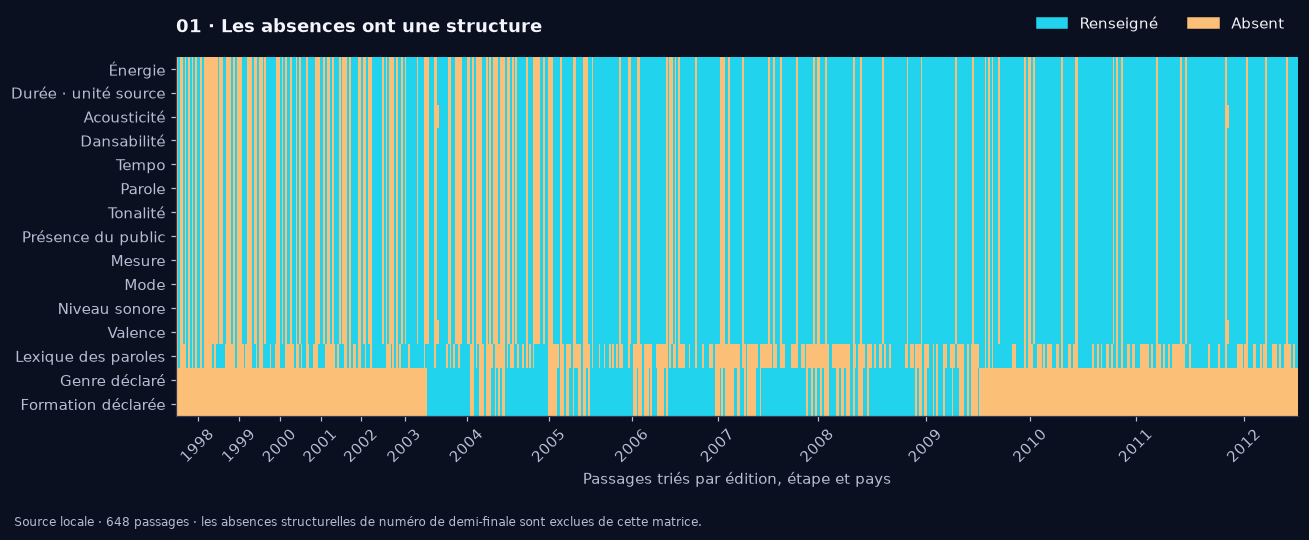

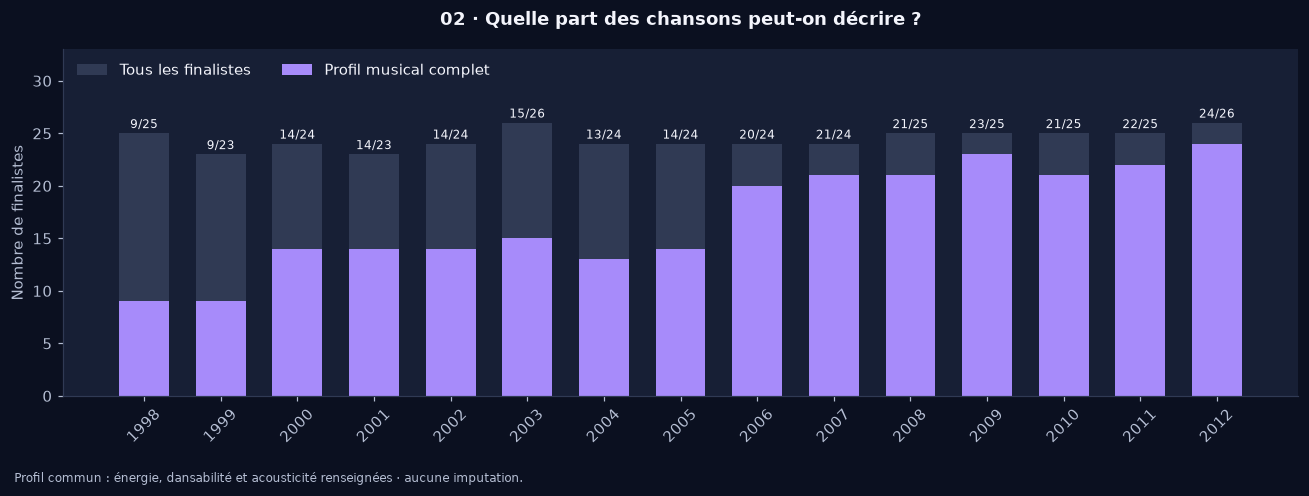

In [11]:
fig,ax=plt.subplots(figsize=(12,5))
ordered=m.sort_values(['Year','etape','Country'])
cols=AUDIO+['Happiness','Artist.gender','Group.Solo']
ax.imshow(ordered[cols].isna().to_numpy().T,aspect='auto',interpolation='nearest',
    cmap=ListedColormap([C['cyan'],C['amber']]),vmin=0,vmax=1)
ax.set_yticks(range(len(cols)),[LABELS.get(c,c) for c in cols])
centers=[];ticks=[]
for y,g in ordered.groupby('Year',sort=True):
    positions=np.flatnonzero(ordered.Year.eq(y));centers.append(positions.mean());ticks.append(str(y))
ax.set_xticks(centers,ticks,rotation=45)
ax.set_title('01 · Les absences ont une structure',loc='left')
ax.set_xlabel('Passages triés par édition, étape et pays')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C['cyan'],label='Renseigné'),Patch(color=C['amber'],label='Absent')],
    loc='upper right',bbox_to_anchor=(1,1.15),ncol=2,frameon=False)
save_figure(fig,'01_matrice_absences','Source locale · 648 passages · les absences structurelles de numéro de demi-finale sont exclues de cette matrice.')
fig,ax=plt.subplots(figsize=(12,4.5))
x=np.arange(len(coverage));ax.bar(x,coverage.finalistes,color=C['grid'],label='Tous les finalistes',width=.65)
ax.bar(x,coverage.profil_complet,color=C['violet'],label='Profil musical complet',width=.65)
for i,row in coverage.iterrows():
    ax.text(i,row.finalistes+.5,f'{int(row.profil_complet)}/{int(row.finalistes)}',ha='center',fontsize=8)
ax.set_xticks(x,coverage.Year.astype(str),rotation=45);ax.set_ylim(0,coverage.finalistes.max()+7)
ax.set_ylabel('Nombre de finalistes');ax.set_title('02 · Quelle part des chansons peut-on décrire ?')
ax.legend(frameon=False,ncol=2,loc='upper left')
save_figure(fig,'02_couverture_finales','Profil commun : énergie, dansabilité et acousticité renseignées · aucune imputation.')
lecture(f'{int(finals.profil_complet.sum())} des {len(finals)} finalistes disposent du profil commun, soit {fr(finals.profil_complet.mean()*100,1)} %. La couverture varie selon les éditions ; une moyenne musicale ne décrit donc pas automatiquement tous les finalistes.')

<a id="etape-8"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">08 · Domaines, valeurs extrêmes et cohérence des étapes</h2>


On vérifie les domaines attendus des indicateurs : indices acoustiques bornés entre 0 et 1, valeurs positives pour tempo et durée, catégories 0-11 pour la tonalité et 0/1 pour le mode. Les valeurs négatives du niveau sonore restent valides ; le dictionnaire local ne précise pas son unité.

Les observations hors de l’intervalle de Tukey (1,5 fois l’écart interquartile) sont signalées à titre exploratoire, jamais supprimées automatiquement. La durée peut désigner une piste ou un extrait plutôt qu’une prestation ; une durée inhabituelle n’autorise pas à corriger l’enregistrement.

Les propriétés musicales répétées sont vérifiées au niveau pays-année avant de construire la table des participations. Les champs qui varient entre étapes restent dans les résultats d’étape.

In [12]:
check('Période attendue',set(m.Year)==set(range(1998,2013)))
check('Clés de passage uniques',not m.duplicated(['Year','Country','etape']).any())
check('Drapeau finale binaire',m['Is.Final'].isin([0,1]).all())
check('Finales sans numéro de demi-finale',m.loc[m['Is.Final'].eq(1),'Semi.Final.Number'].isna().all())
check('Demi-finales numérotées 1 ou 2',m.loc[m['Is.Final'].eq(0),'Semi.Final.Number'].isin([1,2]).all())
check('Aucune demi-finale avant 2004',not ((m.Year<2004)&m['Is.Final'].eq(0)).any())
check('Seconde demi-finale à partir de 2008',not ((m.Year<2008)&m.etape.eq('SF2')).any())
check('Points entiers non négatifs',m.Points.notna().all() and m.Points.ge(0).all())
check('Places entières positives',m.Place.notna().all() and m.Place.ge(1).all())
for col in BOUNDED:
    check(f'Domaine [0,1] : {col}',m[col].dropna().between(0,1).all())
for col in ['duration','tempo','time_signature']:
    check(f'Domaine positif : {col}',m[col].dropna().gt(0).all())
check('Tonalité : 0 à 11',m['key'].dropna().between(0,11).all())
check('Mode : 0 ou 1',m['mode'].dropna().isin([0,1]).all())
check('Langue binaire',m['Song.In.English'].isin([0,1]).all())
check('Genre : catégories source',m['Artist.gender'].dropna().isin(['Female','Male','Both']).all())
check('Formation : catégories source',m['Group.Solo'].dropna().isin(['Solo','Group']).all())
check('Un gagnant par finale',m.loc[m['Is.Final'].eq(1)].groupby('Year').Place.apply(lambda s:s.eq(1).sum()).eq(1).all())
for col in AUDIO+['Happiness','Artist.gender','Group.Solo']:
    counts=m.groupby(['Year','Country'])[col].nunique(dropna=False)
    check(f'Valeur stable entre étapes : {col}',counts.le(1).all())

**Variantes entre passages.** Les champs variables ne sont pas arbitrairement promus au niveau du pays ou de la chanson.

edition,pays,variable,valeurs,decision
2 005,Croatia,Artist,Boris Novkovi? | Boris Novkovi? feat. Lado Members,Conservé par étape ; libellé représentatif issu de la finale si présente
2 006,Armenia,Artist,Andr_ | AndrŠ,Conservé par étape ; libellé représentatif issu de la finale si présente
2 007,Belarus,Artist,Dmitry Koldun | Koldun,Conservé par étape ; libellé représentatif issu de la finale si présente
2 008,Finland,Artist,TerÊsbetoni | Ter†sbetoni,Conservé par étape ; libellé représentatif issu de la finale si présente
2 008,Portugal,Artist,VÑnia Fernandes | Vónia Fernandes,Conservé par étape ; libellé représentatif issu de la finale si présente
2 008,Turkey,Artist,Mor ve _tesi | Mor ve étesi,Conservé par étape ; libellé représentatif issu de la finale si présente
2 010,Bosnia and Herzegovina,Artist,Vuka_in Braji | Vuka_in Braji_,Conservé par étape ; libellé représentatif issu de la finale si présente
2 010,Denmark,Artist,Chan_e and N'evergreen | Chan_e¾and¾N'evergreen,Conservé par étape ; libellé représentatif issu de la finale si présente
2 010,Greece,Artist,Giorgos Alkaios and Friends | Giorgos Alkaios¾and¾Friends,Conservé par étape ; libellé représentatif issu de la finale si présente
2 010,Iceland,Artist,Hera Björk | Hera Bj_rk,Conservé par étape ; libellé représentatif issu de la finale si présente


*25 lignes affichées sur 31 ; le rapport exporté contient le détail.*

ligne_excel,Édition,Pays,etape,Song,Durée source
4,2 009,France,F,Et s'il fallait le faire,"227,973"
7,2 009,Portugal,F,Todas as ruas do amor,"253,466"
11,2 009,Russia,F,Mamo,"170,568"
12,2 009,Azerbaijan,F,Always,"248,334"
24,2 009,United Kingdom,F,It's My Time,"197,474"
28,2 008,United Kingdom,F,Even If,"224,078"
30,2 008,Germany,F,Disappear,"198,048"
31,2 008,Armenia,F,"Qele, Qele","214,180"
37,2 008,Iceland,F,This is My Life,"245,899"
56,2 007,Finland,F,Leave Me Alone,"213,973"


*15 lignes affichées sur 99 ; le rapport exporté contient le détail.*

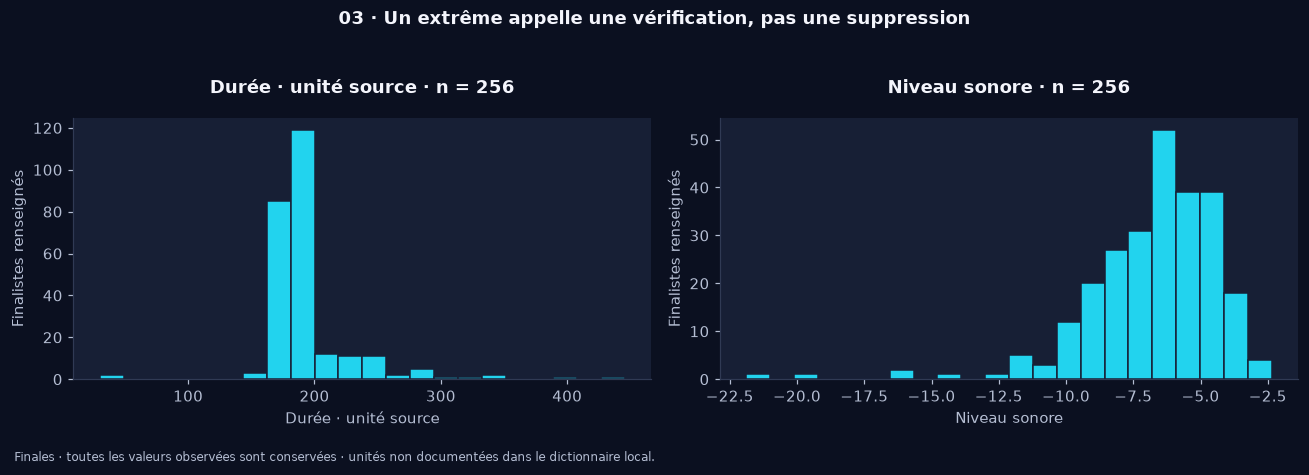

In [13]:
variant_rows=[]
for col in ['Artist','Song','Region','Song.In.English','Song.Quality']:
    for (year,country),group in m.groupby(['Year','Country']):
        values=group[col].dropna().astype(str).unique()
        if len(values)>1:
            variant_rows.append(dict(edition=int(year),pays=country,variable=col,
                valeurs=' | '.join(values),decision='Conservé par étape ; libellé représentatif issu de la finale si présente'))
variants_before=pd.DataFrame(variant_rows)
table(variants_before.loc[~variants_before.variable.eq('Song.Quality')],'Variantes à examiner entre les étapes',limit=25)
q1,q3=m['duration'].quantile([.25,.75]);iqr=q3-q1
m['duree_atypique']=m['duration'].notna()&~m['duration'].between(q1-1.5*iqr,q3+1.5*iqr)
extremes=m.loc[m.duree_atypique,['ligne_excel','Year','Country','etape','Song','duration']].copy()
table(extremes.rename(columns={'Year':'Édition','Country':'Pays','duration':'Durée source'}),'Durées atypiques conservées',limit=15)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axes,['duration','loudness']):
    vals=finals[col].dropna();ax.hist(vals,bins=22,color=C['cyan'],edgecolor=C['panel'])
    ax.set_xlabel(LABELS[col]);ax.set_ylabel('Finalistes renseignés');ax.set_title(f'{LABELS[col]} · n = {len(vals)}')
fig.suptitle('03 · Un extrême appelle une vérification, pas une suppression',fontweight='bold',y=1.04)
save_figure(fig,'03_controle_distributions','Finales · toutes les valeurs observées sont conservées · unités non documentées dans le dictionnaire local.')

<a id="etape-9"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">09 · Rapprocher votes et résultats, corriger avec une preuve</h2>


On harmonise d’abord les noms, puis on additionne les votes reçus par finaliste. Une différence déclenche une vérification ; elle ne désigne pas automatiquement la feuille correcte.

Les corrections ci-dessous ont été vérifiées le **19 octobre 2026** sur les pages de résultats de l’Eurovision. Elles sont intégrées sous forme d’une petite table de référence pour rendre le traitement reproductible hors ligne. Les assertions sur les valeurs « avant » empêchent de réappliquer aveuglément une correction à une nouvelle version de source.

**Cas documentés.** Des scores de finales 2006, 2007 et 2008 sont incorrects dans la feuille descriptive. En 2012, les points et les places de l’Albanie et de l’Azerbaïdjan y sont inversés. En 2010, les résultats agrégés sont corrects : ce sont deux votes estoniens qui sont erronés dans la feuille détaillée. Les corrections textuelles sont limitées à des libellés explicitement confirmés.

La Serbie-et-Monténégro a voté en 2006 après son retrait de la scène : ce cas est confirmé par l’EBU et conservé sans créer une participation fictive.

La vérification officielle porte sur les anomalies identifiées ; elle ne constitue pas un audit historique exhaustif de chaque vote et de chaque demi-finale.

In [14]:
URLS={
 2006:'https://www.eurovision.com/eurovision-song-contest/athens-2006/athens-2006-grand-final/',
 2007:'https://www.eurovision.com/eurovision-song-contest/helsinki-2007/helsinki-2007-grand-final/',
 2008:'https://www.eurovision.com/eurovision-song-contest/belgrade-2008/belgrade-2008-grand-final/',
 2009:'https://www.eurovision.com/eurovision-song-contest/moscow-2009/moscow-2009-grand-final/',
 2010:'https://www.eurovision.com/eurovision-song-contest/oslo-2010/oslo-2010-grand-final/',
 2012:'https://www.eurovision.com/eurovision-song-contest/baku-2012/baku-2012-grand-final/'}
references=pd.DataFrame([{'edition':year,'organisme':'Eurovision / EBU','date_verification':VERIFY_DATE,
    'url':url,'usage':'Vérification ciblée des scores, votes et libellés ; pas de collecte exhaustive'} for year,url in URLS.items()])
for year,url in URLS.items(): display(Markdown(f'- [Résultats officiels de la finale {year}]({url})'))
def reconcile(meta,votes):
    totals=votes.groupby(['Year','Country'],as_index=False).Score.sum().rename(columns={'Score':'somme_votes'})
    result=meta.loc[meta['Is.Final'].eq(1),['Year','Country','Points','Place']].merge(
        totals,on=['Year','Country'],how='outer',validate='one_to_one',indicator=True)
    result['ecart']=result.somme_votes-result.Points
    return result.sort_values(['Year','Country']).reset_index(drop=True)
recon_before=reconcile(m,v)
table(recon_before.loc[recon_before.ecart.ne(0)],'Écarts repérés avant correction officielle',limit=20)

- [Résultats officiels de la finale 2006](https://www.eurovision.com/eurovision-song-contest/athens-2006/athens-2006-grand-final/)

- [Résultats officiels de la finale 2007](https://www.eurovision.com/eurovision-song-contest/helsinki-2007/helsinki-2007-grand-final/)

- [Résultats officiels de la finale 2008](https://www.eurovision.com/eurovision-song-contest/belgrade-2008/belgrade-2008-grand-final/)

- [Résultats officiels de la finale 2009](https://www.eurovision.com/eurovision-song-contest/moscow-2009/moscow-2009-grand-final/)

- [Résultats officiels de la finale 2010](https://www.eurovision.com/eurovision-song-contest/oslo-2010/oslo-2010-grand-final/)

- [Résultats officiels de la finale 2012](https://www.eurovision.com/eurovision-song-contest/baku-2012/baku-2012-grand-final/)

Year,Country,Points,Place,somme_votes,_merge,ecart
2 006,Romania,176,4,172,both,-4
2 007,Moldova,107,10,109,both,2
2 008,Albania,43,17,55,both,12
2 008,Armenia,198,4,199,both,1
2 008,Azerbaijan,124,8,132,both,8
2 008,Bosnia and Herzegovina,105,10,110,both,5
2 008,Croatia,42,21,44,both,2
2 008,Greece,215,3,218,both,3
2 008,Russia,266,1,272,both,6
2 008,Serbia,150,6,160,both,10


**Corriger les résultats agrégés.** Chaque remplacement exige une correspondance unique et la valeur source attendue.

In [15]:
score_fixes=[(2006,'Romania',176,172),(2007,'Moldova',107,109),
 (2008,'Albania',43,55),(2008,'Armenia',198,199),(2008,'Azerbaijan',124,132),
 (2008,'Bosnia and Herzegovina',105,110),(2008,'Croatia',42,44),(2008,'Greece',215,218),
 (2008,'Russia',266,272),(2008,'Serbia',150,160),(2008,'Turkey',131,138),(2008,'Ukraine',226,230),
 (2012,'Albania',150,146),(2012,'Azerbaijan',146,150)]
corrections=[]
for year,country,old,new in score_fixes:
    corrections.append(dict(table='eurovision_meta',edition=year,pays=country,etape='F',
        variable='Points',avant=old,apres=new,reference=URLS[year]))
for country,old,new in [('Albania',4,5),('Azerbaijan',5,4)]:
    corrections.append(dict(table='eurovision_meta',edition=2012,pays=country,etape='F',
        variable='Place',avant=old,apres=new,reference=URLS[2012]))
for fix in corrections:
    mask=m.Year.eq(fix['edition'])&m.Country.eq(fix['pays'])&m.etape.eq(fix['etape'])
    check(f"Correction ciblée : {fix['edition']} {fix['pays']} {fix['variable']}",
          int(mask.sum())==1 and m.loc[mask,fix['variable']].iloc[0]==fix['avant'])
    idx=m.index[mask][0]
    log_change('eurovision_meta',m.at[idx,'ligne_excel'],fix['variable'],fix['avant'],fix['apres'],
        'CORRECTION_OFFICIELLE','Valeur confirmée sur le classement officiel',fix['reference'])
    m.loc[mask,fix['variable']]=fix['apres']

**Corriger les votes détaillés de 2010.** Les deux valeurs estoniennes sont vérifiées individuellement sur la page officielle.

In [16]:
# Deux cellules vérifiées dans « Estonia / Points given », finale 2010.
for country,old,new in [('Denmark',8,5),('Turkey',0,6)]:
    mask=v.Year.eq(2010)&v.Giver.eq('Estonia')&v.Country.eq(country)
    check('Vote estonien ciblé : '+country,int(mask.sum())==1 and v.loc[mask,'Score'].iloc[0]==old)
    idx=v.index[mask][0]
    log_change('Voting Final',v.at[idx,'ligne_excel'],'Score',old,new,'CORRECTION_OFFICIELLE',
        f'Estonie vers {country} : valeur du vote confirmée, pas une allocation par différence',URLS[2010])
    corrections.append(dict(table='Voting Final',edition=2010,pays=country,etape='F / Giver=Estonia',
        variable='Score',avant=old,apres=new,reference=URLS[2010]))
    v.loc[mask,'Score']=new

**Réparer les libellés avec une référence.** Les corrections initiales reposent sur les pages officielles. La revue complémentaire couvre les 135 cellules signalées, soit 112 références pays-édition-champ. Elle utilise les listes de participants et leurs liens d’artistes, avec références complémentaires pour les variantes de noms. Les titres et noms sont vérifiés sur leur participation exacte ; aucune correspondance approximative ni suppression globale des accents n’est appliquée. Une ponctuation valide, comme le point d’interrogation de *Is It True?*, est conservée.

In [17]:
# Libellés confirmés pour une participation ; mêmes libellés d’affichage à ses étapes.
label_fixes=[
 (2006,'Armenia','Artist','André'),(2007,'Belarus','Artist','Dmitry Koldun'),
 (2007,'Turkey','Song','Shake It Up Shekerim'),
 (2008,'Albania','Song','Zemrën E Lamë Peng'),(2008,'Armenia','Song','Qele, Qele'),
 (2008,'Bosnia and Herzegovina','Song','Pokušaj'),(2008,'Finland','Song','Missä Miehet Ratsastaa'),
 (2008,'Finland','Artist','Teräsbetoni'),(2008,'Iceland','Song','This Is My Life'),
 (2008,'Portugal','Artist','Vânia Fernandes'),(2008,'Turkey','Artist','Mor ve Ötesi'),
 (2009,'Estonia','Song','Rändajad'),(2009,'Turkey','Song','Düm Tek Tek'),
 (2010,'Bosnia and Herzegovina','Artist','Vukašin Brajić'),
 (2010,'Denmark','Artist',"Chanée & N'evergreen"),(2010,'Greece','Artist','Giorgos Alkaios & Friends'),
 (2010,'Greece','Song','OPA'),(2010,'Iceland','Artist','Hera Björk'),
 (2010,'Moldova','Artist','Sunstroke Project & Olia Tira'),(2010,'Romania','Artist','Paula Seling & Ovi'),
 (2010,'Serbia','Artist','Milan Stanković'),(2010,'Serbia','Song','Ovo Je Balkan'),
 (2012,'Iceland','Artist','Greta Salóme & Jónsi')]
for year,country,col,value in label_fixes:
    mask=m.Year.eq(year)&m.Country.eq(country)
    check(f'Libellé documenté : {year} {country} {col}',mask.any())
    for idx in m.index[mask]:
        log_change('eurovision_meta',m.at[idx,'ligne_excel'],col,m.at[idx,col],value,
            'LIBELLE_OFFICIEL','Libellé explicite de la participation, source de chaque étape conservée dans audit_source',URLS[year])
        m.at[idx,col]=value

# Revue complémentaire du 20 octobre : références figées pour une reproduction hors ligne.
# Clé exacte pays-édition-champ ; variantes brutes attendues contrôlées avant écriture.
references_libelles = json.loads(r'''[{"edition": 2009, "pays": "Iceland", "variable": "Song", "valeurs_attendues": ["Is It True?"], "valeur_validee": "Is It True?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2009", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2009, "pays": "Spain", "variable": "Song", "valeurs_attendues": ["La noche es para m"], "valeur_validee": "La noche es para mí", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2009", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2008, "pays": "Portugal", "variable": "Song", "valeurs_attendues": ["Senhora do mar (Negras _guas)"], "valeur_validee": "Senhora do mar (Negras águas)", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2008", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2008, "pays": "France", "variable": "Artist", "valeurs_attendues": ["S_bastien Tellier"], "valeur_validee": "Sébastien Tellier", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2008", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2008, "pays": "Serbia", "variable": "Artist", "valeurs_attendues": ["Jelena Toma?evi?"], "valeur_validee": "Jelena Tomašević feat. Bora Dugić", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2008", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "France", "variable": "Song", "valeurs_attendues": ["L'amour _ La Franaise"], "valeur_validee": "L'Amour à la française", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "Serbia", "variable": "Artist", "valeurs_attendues": ["Marija ?erifovi?"], "valeur_validee": "Marija Šerifović", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "Turkey", "variable": "Artist", "valeurs_attendues": ["Kenan Do?ulu"], "valeur_validee": "Kenan Doğulu", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2006, "pays": "Romania", "variable": "Artist", "valeurs_attendues": ["Mihai Tr?istariu"], "valeur_validee": "Mihai Trăistariu", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2006, "pays": "France", "variable": "Song", "valeurs_attendues": ["Il _tait temps"], "valeur_validee": "Il était temps", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2006, "pays": "Croatia", "variable": "Song", "valeurs_attendues": ["Moja ?tikla"], "valeur_validee": "Moja štikla", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2006, "pays": "Turkey", "variable": "Artist", "valeurs_attendues": ["Sibel Tzn"], "valeur_validee": "Sibel Tüzün", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2006, "pays": "Turkey", "variable": "Song", "valeurs_attendues": ["Sper Star"], "valeur_validee": "Süper Star", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Hungary", "variable": "Song", "valeurs_attendues": ["Forogj, vil_g!"], "valeur_validee": "Forogj, világ", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Romania", "variable": "Artist", "valeurs_attendues": ["Lumini?a Anghel and Sistem"], "valeur_validee": "Luminița Anghel and Sistem", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Turkey", "variable": "Artist", "valeurs_attendues": ["Glseren"], "valeur_validee": "Gülseren", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Moldova", "variable": "Artist", "valeurs_attendues": ["Zdob ?i Zdub"], "valeur_validee": "Zdob și Zdub", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Spain", "variable": "Song", "valeurs_attendues": ["Brujera"], "valeur_validee": "Brujería", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Macedonia", "variable": "Artist", "valeurs_attendues": ["Martin Vu?i?"], "valeur_validee": "Martin Vučić", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Croatia", "variable": "Artist", "valeurs_attendues": ["Boris Novkovi?", "Boris Novkovi? feat. Lado Members"], "valeur_validee": "Boris Novković feat. Lado Members", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "https://www.eurovision.com/eurovision-song-contest/kyiv-2005/participants/boris-novkovic-feat-lado-members/", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Norway", "variable": "Artist", "valeurs_attendues": ["Knut Anders S_rum"], "valeur_validee": "Knut Anders Sørum", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Serbia and Montenegro", "variable": "Artist", "valeurs_attendues": ["?eljko Joksimovi?"], "valeur_validee": "Željko Joksimović and Ad Hoc Orchestra", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Croatia", "variable": "Artist", "valeurs_attendues": ["Ivan Mikuli?"], "valeur_validee": "Ivan Mikulić", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Macedonia", "variable": "Artist", "valeurs_attendues": ["To?e Proeski"], "valeur_validee": "Toše Proeski", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Poland", "variable": "Artist", "valeurs_attendues": ["Blue Caf_"], "valeur_validee": "Blue Café", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2003, "pays": "Croatia", "variable": "Song", "valeurs_attendues": ["Vi?e nisam tvoja"], "valeur_validee": "Više nisam tvoja", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2003", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2003, "pays": "Norway", "variable": "Artist", "valeurs_attendues": ["Jostein Hasselg_rd"], "valeur_validee": "Jostein Hasselgård", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2003", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2003, "pays": "France", "variable": "Artist", "valeurs_attendues": ["Louisa Ba¾leche"], "valeur_validee": "Louisa Baïleche", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2003", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2003, "pays": "Poland", "variable": "Song", "valeurs_attendues": ["Keine Grenzen-?adnych granic"], "valeur_validee": "Keine Grenzen \u2013 Żadnych granic", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2003", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2002, "pays": "Croatia", "variable": "Artist", "valeurs_attendues": ["Vesna Pisarovi?"], "valeur_validee": "Vesna Pisarović", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2002", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2002, "pays": "Macedonia", "variable": "Artist", "valeurs_attendues": ["Karolina Go?eva"], "valeur_validee": "Karolina Gočeva", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2002", "reference_complementaire": "https://en.wikipedia.org/wiki/Karolina_Gočeva", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2002, "pays": "Bosnia and Herzegovina", "variable": "Artist", "valeurs_attendues": ["Maja Tati?"], "valeur_validee": "Maja Tatić", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2002", "reference_complementaire": "https://en.wikipedia.org/wiki/Maja_Tatić", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2002, "pays": "France", "variable": "Artist", "valeurs_attendues": ["Sandrine Fran_ois"], "valeur_validee": "Sandrine François", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2002", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2001, "pays": "Bosnia and Herzegovina", "variable": "Artist", "valeurs_attendues": ["Nino Pr?e?"], "valeur_validee": "Nino Pršeš", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2001", "reference_complementaire": "https://en.wikipedia.org/wiki/Nino_Pršeš", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2001, "pays": "Turkey", "variable": "Artist", "valeurs_attendues": ["Sedat Yce"], "valeur_validee": "Sedat Yüce", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2001", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2001, "pays": "Slovenia", "variable": "Artist", "valeurs_attendues": ["Nu?a Derenda"], "valeur_validee": "Nuša Derenda", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2001", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2000, "pays": "Spain", "variable": "Artist", "valeurs_attendues": ["Serafn Zubiri"], "valeur_validee": "Serafín Zubiri", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2000", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2000, "pays": "Spain", "variable": "Song", "valeurs_attendues": ["Colgado de un sue_o"], "valeur_validee": "Colgado de un sueño", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2000", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2000, "pays": "Germany", "variable": "Song", "valeurs_attendues": ["Wadde hadde dudde da?"], "valeur_validee": "Wadde hadde dudde da?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2000", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2000, "pays": "Switzerland", "variable": "Song", "valeurs_attendues": ["La vita cos'_?"], "valeur_validee": "La vita cos'è?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2000", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2000, "pays": "Croatia", "variable": "Song", "valeurs_attendues": ["Kad zaspu an?eli"], "valeur_validee": "Kad zaspu anđeli", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2000", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2000, "pays": "Finland", "variable": "Artist", "valeurs_attendues": ["Nina str”m"], "valeur_validee": "Nina Åström", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2000", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2000, "pays": "Turkey", "variable": "Artist", "valeurs_attendues": ["Pnar Ayhan & The SOS"], "valeur_validee": "Pınar Ayhan & The SOS", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2000", "reference_complementaire": "https://en.wikipedia.org/wiki/Pınar_Ayhan | https://en.wikipedia.org/wiki/Grup_SOS?action=edit&redlink=1", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Lithuania", "variable": "Artist", "valeurs_attendues": ["Aist?"], "valeur_validee": "Aistė", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Croatia", "variable": "Artist", "valeurs_attendues": ["Doris Dragovi?"], "valeur_validee": "Doris Dragović", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "https://en.wikipedia.org/wiki/Doris_Dragović", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Slovenia", "variable": "Artist", "valeurs_attendues": ["Darja ?vajger"], "valeur_validee": "Darja Švajger", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Turkey", "variable": "Artist", "valeurs_attendues": ["Tu?ba _nal"], "valeur_validee": "Tuba Önal and Grup Mistik", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Turkey", "variable": "Song", "valeurs_attendues": ["D”n Artk"], "valeur_validee": "Dön Artık", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Poland", "variable": "Artist", "valeurs_attendues": ["Mietek Szcze?niak"], "valeur_validee": "Mietek Szcześniak", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Portugal", "variable": "Song", "valeurs_attendues": ["Como tudo come_ou"], "valeur_validee": "Como tudo começou", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Germany", "variable": "Artist", "valeurs_attendues": ["Srpriz"], "valeur_validee": "Sürpriz", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1999, "pays": "Bosnia and Herzegovina", "variable": "Artist", "valeurs_attendues": ["Dino & B_atrice"], "valeur_validee": "Dino and Béatrice", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1999", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "France", "variable": "Song", "valeurs_attendues": ["O† aller"], "valeur_validee": "Où aller", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Spain", "variable": "Song", "valeurs_attendues": ["ëQu_ voy a hacer sin ti?"], "valeur_validee": "¿Qué voy a hacer sin ti?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Slovakia", "variable": "Artist", "valeurs_attendues": ["Katarna Hasprov_"], "valeur_validee": "Katarína Hasprová", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Hungary", "variable": "Song", "valeurs_attendues": ["A holnap m_r nem lesz szomor£"], "valeur_validee": "A holnap már nem lesz szomorú", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Slovenia", "variable": "Song", "valeurs_attendues": ["Naj bogovi sli?ijo"], "valeur_validee": "Naj bogovi slišijo", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Ireland", "variable": "Song", "valeurs_attendues": ["Is Always Over Now?"], "valeur_validee": "Is Always Over Now?", "reference": "https://www.eurovision.com/eurovision-song-contest/birmingham-1998/participants/dawn/", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Portugal", "variable": "Song", "valeurs_attendues": ["Se eu te pudesse abra_ar"], "valeur_validee": "Se eu te pudesse abraçar", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Romania", "variable": "Artist", "valeurs_attendues": ["M?lina Olinescu"], "valeur_validee": "Mălina Olinescu", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "United Kingdom", "variable": "Song", "valeurs_attendues": ["Where Are You?"], "valeur_validee": "Where Are You?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Belgium", "variable": "Artist", "valeurs_attendues": ["M_lanie Cohl"], "valeur_validee": "Mélanie Cohl", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Turkey", "variable": "Artist", "valeurs_attendues": ["Tzmen"], "valeur_validee": "Tüzmen", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 1998, "pays": "Turkey", "variable": "Song", "valeurs_attendues": ["Unutamazsn"], "valeur_validee": "Unutamazsın", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_1998", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2011, "pays": "Hungary", "variable": "Song", "valeurs_attendues": ["What About My Dreams?"], "valeur_validee": "What About My Dreams?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2011", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2011, "pays": "Lithuania", "variable": "Artist", "valeurs_attendues": ["Evelina Sa_enko"], "valeur_validee": "Evelina Sašenko", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2011", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2011, "pays": "Moldova", "variable": "Artist", "valeurs_attendues": ["Zdob _i Zdub"], "valeur_validee": "Zdob și Zdub", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2011", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2011, "pays": "Serbia", "variable": "Song", "valeurs_attendues": ["_aroban"], "valeur_validee": "Čaroban", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2011", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2011, "pays": "Spain", "variable": "Artist", "valeurs_attendues": ["Luca P_rez"], "valeur_validee": "Lucía Pérez", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2011", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "Italy", "variable": "Song", "valeurs_attendues": ["L'amore  femmina (Out of Love)"], "valeur_validee": "L'amore è femmina (Out of Love)", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "Moldova", "variable": "Song", "valeurs_attendues": ["L_utar"], "valeur_validee": "Lăutar", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "Serbia", "variable": "Artist", "valeurs_attendues": ["_eljko Joksimovi_"], "valeur_validee": "Željko Joksimović", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "Spain", "variable": "Song", "valeurs_attendues": ["Qu_date conmigo"], "valeur_validee": "Quédate conmigo", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Belarus", "variable": "Artist", "valeurs_attendues": ["3+2¾feat¾Robert Wells"], "valeur_validee": "3+2 feat. Robert Wells", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Cyprus", "variable": "Artist", "valeurs_attendues": ["Jon Lilygreen¾and¾The Islanders"], "valeur_validee": "Jon Lilygreen and the Islanders", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "France", "variable": "Song", "valeurs_attendues": ["Allez Ola Ol_"], "valeur_validee": "Allez Ola Olé", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Israel", "variable": "Song", "valeurs_attendues": ["Milim (_____)"], "valeur_validee": "Milim (מילים)", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Spain", "variable": "Song", "valeurs_attendues": ["Algo peque_ito"], "valeur_validee": "Algo pequeñito", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2009, "pays": "Montenegro", "variable": "Artist", "valeurs_attendues": ["Andrea Demirovi?"], "valeur_validee": "Andrea Demirović", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2009", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2009, "pays": "Belgium", "variable": "Artist", "valeurs_attendues": ["Patrick Ouch_ne"], "valeur_validee": "Patrick Ouchène", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2009", "reference_complementaire": "https://en.wikipedia.org/wiki/Patrick_Ouchène", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2009, "pays": "Slovakia", "variable": "Artist", "valeurs_attendues": ["Kamil Mikul?k and Nela"], "valeur_validee": "Kamil Mikulčík and Nela Pocisková", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2009", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2009, "pays": "Slovakia", "variable": "Song", "valeurs_attendues": ["Le? tmou"], "valeur_validee": "Leť tmou", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2009", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2008, "pays": "Montenegro", "variable": "Artist", "valeurs_attendues": ["Stefan Filipovi?"], "valeur_validee": "Stefan Filipović", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2008", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2008, "pays": "Czech Republic", "variable": "Artist", "valeurs_attendues": ["Tereza Kerndlov_"], "valeur_validee": "Tereza Kerndlová", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2008", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2008, "pays": "Macedonia", "variable": "Artist", "valeurs_attendues": ["Tamara, Vr?ak and Adrijan"], "valeur_validee": "Tamara, Vrčak and Adrijan", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2008", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "Iceland", "variable": "Artist", "valeurs_attendues": ["Eirkur Hauksson"], "valeur_validee": "Eiríkur Hauksson", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "Montenegro", "variable": "Song", "valeurs_attendues": ["'Ajde, kro?i"], "valeur_validee": "' Ajde, kroči", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "Croatia", "variable": "Artist", "valeurs_attendues": ["Dragonfly feat. Dado Topi?"], "valeur_validee": "Dragonfly feat. Dado Topić", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "Czech Republic", "variable": "Artist", "valeurs_attendues": ["Kab_t"], "valeur_validee": "Kabát", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2007, "pays": "Czech Republic", "variable": "Song", "valeurs_attendues": ["Mal_ d_ma"], "valeur_validee": "Malá dáma", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2007", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2006, "pays": "Slovenia", "variable": "Artist", "valeurs_attendues": ["An?ej De?an"], "valeur_validee": "Anžej Dežan", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2006, "pays": "Albania", "variable": "Song", "valeurs_attendues": ["Zjarr e ftoht_"], "valeur_validee": "Zjarr e ftohtë", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Austria", "variable": "Song", "valeurs_attendues": ["Y as"], "valeur_validee": "Y así", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Finland", "variable": "Song", "valeurs_attendues": ["Why?"], "valeur_validee": "Why?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2005, "pays": "Ireland", "variable": "Song", "valeurs_attendues": ["Love?"], "valeur_validee": "Love?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2005", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Finland", "variable": "Artist", "valeurs_attendues": ["Jari Sillanp††"], "valeur_validee": "Jari Sillanpää", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Monaco", "variable": "Song", "valeurs_attendues": ["Notre plan_te"], "valeur_validee": "Notre planète", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Lithuania", "variable": "Song", "valeurs_attendues": ["What's Happened To Your Love?"], "valeur_validee": "What's Happened To Your Love?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2004, "pays": "Estonia", "variable": "Artist", "valeurs_attendues": ["Neiok_s_"], "valeur_validee": "Neiokõsõ", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2004", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2011, "pays": "Cyprus", "variable": "Song", "valeurs_attendues": ["San Aggelos SAgapisa"], "valeur_validee": "San aggelos s'agapisa", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2011", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2011, "pays": "Albania", "variable": "Artist", "valeurs_attendues": ["Aurela Gae"], "valeur_validee": "Aurela Gaçe", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2011", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "Belgium", "variable": "Song", "valeurs_attendues": ["Would You?"], "valeur_validee": "Would You?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "Croatia", "variable": "Artist", "valeurs_attendues": ["Nina Badri_"], "valeur_validee": "Nina Badrić", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "Finland", "variable": "Song", "valeurs_attendues": ["N_r Jag Blundar"], "valeur_validee": "När jag blundar", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2012, "pays": "San Marino", "variable": "Song", "valeurs_attendues": ["The Social Network Song (Oh Oh _ Uh - Oh Oh)"], "valeur_validee": "The Social Network Song (Oh Oh \u2013 Uh \u2013 Oh Oh)", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2012", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Bulgaria", "variable": "Song", "valeurs_attendues": ["Angel si ti (_____ __ __)"], "valeur_validee": "Angel si ti (Ангел си ти)", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Estonia", "variable": "Artist", "valeurs_attendues": ["Malcolm Lincoln¾and¾Manpower 4"], "valeur_validee": "Malcolm Lincoln & Manpower 4", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "https://en.wikipedia.org/wiki/Estonia_in_the_Eurovision_Song_Contest_2010", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Finland", "variable": "Song", "valeurs_attendues": ["Ty_lki ell__"], "valeur_validee": "Työlki ellää", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Latvia", "variable": "Song", "valeurs_attendues": ["What For?"], "valeur_validee": "What For?", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Ponctuation valide ou variante typographique reconnue ; valeur source conservée.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Macedonia", "variable": "Artist", "valeurs_attendues": ["Gjoko Taneski,¾Billy Zver¾and¾Pej_in"], "valeur_validee": "Gjoko Taneski, Billy Zver and Pejčin", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "https://en.wikipedia.org/wiki/Macedonia_in_the_Eurovision_Song_Contest_2010", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Poland", "variable": "Artist", "valeurs_attendues": ["Marcin Mrozi_ski"], "valeur_validee": "Marcin Mroziński", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}, {"edition": 2010, "pays": "Slovenia", "variable": "Artist", "valeurs_attendues": ["Ansambel _lindra¾and¾Kalamari"], "valeur_validee": "Ansambel Žlindra and Kalamari", "reference": "https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2010", "reference_complementaire": "", "decision": "Graphie vérifiée par pays-édition ; aucune correspondance approximative.", "date_verification": "2026-10-20"}]''')
revue_libelles=[]
for ref in references_libelles:
    year,country,col=ref['edition'],ref['pays'],ref['variable']
    mask=m.Year.eq(year)&m.Country.eq(country)
    expected={normalize_text(x) for x in ref['valeurs_attendues']}
    actual=set(m.loc[mask,col].astype(str))
    if not mask.any() or not actual.issubset(expected):
        raise ValueError(f'Référence de libellé à revoir : {year} {country} {col} : {actual}')
    for idx in m.index[mask]:
        before=m.at[idx,col];after=ref['valeur_validee']
        revue_libelles.append(dict(ligne_excel=int(m.at[idx,'ligne_excel']),edition=year,pays=country,
            variable=col,avant=before,apres=after,action='Corrigé' if before!=after else 'Validé sans modification',
            justification=ref['decision'],reference=ref['reference'],
            reference_complementaire=ref['reference_complementaire'],date_verification=ref['date_verification']))
        log_change('eurovision_meta',m.at[idx,'ligne_excel'],col,before,after,
            'LIBELLE_REFERENCE_POINT2',ref['decision'],ref['reference'])
        m.at[idx,col]=after
revue_libelles=pd.DataFrame(revue_libelles)
libelles_verifies={(r['edition'],r['pays'],r['variable'],r['valeur_validee']) for r in references_libelles}
check('Revue des 135 cellules signalées',len(revue_libelles)==135)
check('Références uniques pays-édition-champ',len(libelles_verifies)==112)
table(revue_libelles[['edition','pays','variable','avant','apres','action']],'Revue des libellés : correction ou ponctuation valide',limit=15)


edition,pays,variable,avant,apres,action
2 009,Iceland,Song,Is It True?,Is It True?,Validé sans modification
2 009,Iceland,Song,Is It True?,Is It True?,Validé sans modification
2 009,Spain,Song,La noche es para m,La noche es para mí,Corrigé
2 008,Portugal,Song,Senhora do mar (Negras _guas),Senhora do mar (Negras águas),Corrigé
2 008,Portugal,Song,Senhora do mar (Negras _guas),Senhora do mar (Negras águas),Corrigé
2 008,France,Artist,S_bastien Tellier,Sébastien Tellier,Corrigé
2 008,Serbia,Artist,Jelena Toma?evi?,Jelena Tomašević feat. Bora Dugić,Corrigé
2 007,France,Song,L'amour _ La Franaise,L'Amour à la française,Corrigé
2 007,Serbia,Artist,Marija ?erifovi?,Marija Šerifović,Corrigé
2 007,Serbia,Artist,Marija ?erifovi?,Marija Šerifović,Corrigé


*15 lignes affichées sur 135 ; le rapport exporté contient le détail.*

**Valider le rapprochement.** On contrôle les totaux reçus, le barème de chaque donneur et la présence des votes nuls.

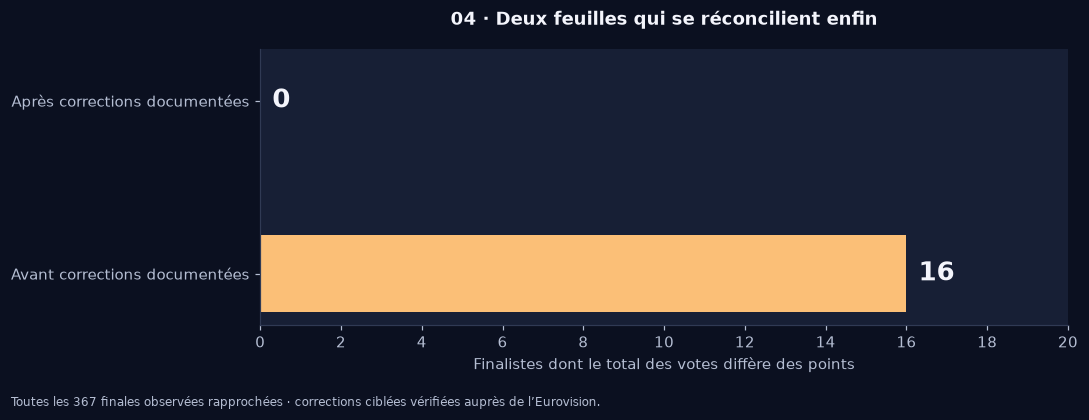

In [18]:
corrections_officielles=pd.DataFrame(corrections)
recon_after=reconcile(m,v)
check('Tous les votes rattachés à un finaliste',recon_after['_merge'].eq('both').all())
check('Votes et points : toutes les finales rapprochées',recon_after.ecart.eq(0).all())
check('Votes : aucune clé dupliquée',not v.duplicated(['Year','Country','Giver']).any())
check('Votes : aucun auto-vote',v.Country.ne(v.Giver).all())
check('Votes : barème valide',v.Score.isin([0,1,2,3,4,5,6,7,8,10,12]).all())
giver_totals=v.groupby(['Year','Giver']).Score.sum()
check('Votes : 58 points par donneur',giver_totals.eq(58).all())
expected_awards=[1,2,3,4,5,6,7,8,10,12]
check('Votes : chacun des dix points attribués une fois',v.groupby(['Year','Giver']).Score.apply(
    lambda s:sorted(s.loc[s.gt(0)].astype(int).tolist())==expected_awards).all())
check('Votes : matrice complète donneurs × finalistes hors auto-vote',all(
    set(g.Country)==set(m.loc[m.Year.eq(year)&m['Is.Final'].eq(1),'Country'])-{giver}
    for (year,giver),g in v.groupby(['Year','Giver'])))
finals=m.loc[m['Is.Final'].eq(1)].copy()
fig,ax=plt.subplots(figsize=(10,3.8))
vals=[int(recon_before.ecart.ne(0).sum()),int(recon_after.ecart.ne(0).sum())]
ax.barh(['Avant corrections documentées','Après corrections documentées'],vals,color=[C['amber'],C['cyan']],height=.45)
for i,value in enumerate(vals):ax.text(value+.3,i,str(value),va='center',fontweight='bold',fontsize=17)
ax.set_xlim(0,max(vals)+4);ax.set_xlabel('Finalistes dont le total des votes diffère des points');ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title('04 · Deux feuilles qui se réconcilient enfin')
save_figure(fig,'04_rapprochement_votes','Toutes les 367 finales observées rapprochées · corrections ciblées vérifiées auprès de l’Eurovision.')
lecture(f'{vals[0]} écarts de totaux ont été identifiés. Après les corrections sourcées, les {len(recon_after)} totaux coïncident et chaque donneur attribue exactement les dix notes attendues. Ces contrôles prouvent la cohérence des tables, pas l’exactitude exhaustive de toutes les cellules historiques.')

<a id="etape-10"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">10 · Construire cinq tables sans doubles comptes</h2>


Les attributs musicaux et les catégories stables sont placés dans `participations`. Pour chaque participation, la ligne représentative est celle de la finale si elle existe, sinon celle de la demi-finale. Cette règle ne calcule aucune moyenne et ne remplit aucune absence. `ligne_representative` permet de remonter à l’observation sélectionnée.

Les points, le rang, `Song.Quality`, la langue et le regroupement régional de la source restent au niveau de l’étape. Les deux niveaux de points normalisés sont conservés séparément : `normalized_points_source` est la valeur d’origine ; `part_points_etape` est un calcul explicite **points corrigés / total corrigé des points de cette année et de cette étape**. Les notes des deux demi-finales ne sont pas mélangées. Ce ratio ne neutralise pas toutes les différences de règles ou de nombre de votants.

Pour le futur modèle Power BI : `editions → participations → resultats_etapes`, `pays → participations`, puis `participations → votes_finale` pour le destinataire. Le pays donneur utilise une **dimension de rôle séparée** issue de `pays`. Les relations seront à sens unique pour éviter les chemins ambigus ; aucun changement de modèle n’est effectué ici.

In [19]:
COUNTRY_FR={
'Albania':'Albanie','Andorra':'Andorre','Armenia':'Arménie','Austria':'Autriche','Azerbaijan':'Azerbaïdjan',
'Belarus':'Biélorussie','Belgium':'Belgique','Bosnia and Herzegovina':'Bosnie-Herzégovine',
'Bulgaria':'Bulgarie','Croatia':'Croatie','Cyprus':'Chypre','Czech Republic':'République tchèque',
'Denmark':'Danemark','Estonia':'Estonie','Finland':'Finlande','France':'France','Georgia':'Géorgie',
'Germany':'Allemagne','Greece':'Grèce','Hungary':'Hongrie','Iceland':'Islande','Ireland':'Irlande',
'Israel':'Israël','Italy':'Italie','Latvia':'Lettonie','Lithuania':'Lituanie','Macedonia':'Macédoine (libellé historique)',
'Malta':'Malte','Moldova':'Moldavie','Monaco':'Monaco','Montenegro':'Monténégro','Netherlands':'Pays-Bas',
'Norway':'Norvège','Poland':'Pologne','Portugal':'Portugal','Romania':'Roumanie','Russia':'Russie',
'San Marino':'Saint-Marin','Serbia':'Serbie','Serbia and Montenegro':'Serbie-et-Monténégro',
'Slovakia':'Slovaquie','Slovenia':'Slovénie','Spain':'Espagne','Sweden':'Suède','Switzerland':'Suisse',
'Turkey':'Turquie','Ukraine':'Ukraine','United Kingdom':'Royaume-Uni'}
check('Correspondance française complète',set(m.Country)==set(COUNTRY_FR))
pays=pd.DataFrame({'pays_source':sorted(COUNTRY_FR)})
pays.insert(0,'pays_id',[f'C{i:03d}' for i in range(1,len(pays)+1)])
pays['pays_fr']=pays.pays_source.map(COUNTRY_FR)
pays['entite_historique']=pays.pays_source.eq('Serbia and Montenegro')
country_keys=pays.set_index('pays_source').pays_id.to_dict()
m['pays_id']=m.Country.map(country_keys)
m['participation_id']=m.Year.astype(str)+'_'+m.pays_id
m['resultat_id']=m.participation_id+'_'+m.etape
m['points_source']=pd.to_numeric(raw.Points,errors='raise').astype('Int64')
m['place_source']=pd.to_numeric(raw.Place,errors='raise').astype('Int64')
m['part_points_etape']=m.Points/m.groupby(['Year','etape']).Points.transform('sum')
m['correction_resultat']=m.Points.ne(m.points_source)|m.Place.ne(m.place_source)
normalization=m[['ligne_excel','Year','Country','etape','Normalized.Points','part_points_etape']].copy()
normalization['ecart']=normalization.part_points_etape-normalization['Normalized.Points']
normalization['ecart_significatif']=normalization.ecart.abs().gt(1e-10)
table(normalization.loc[normalization.ecart_significatif], 'Normalisation : formule source et formule explicite ne sont pas interchangeables',limit=8)
lecture(f'{int(normalization.ecart_significatif.sum())} passages diffèrent entre la normalisation de la source et notre part des points de l’étape, après correction. La formule et les données sources sont conservées pour rendre cette différence visible.')

ligne_excel,Year,Country,etape,Normalized.Points,part_points_etape,ecart,ecart_significatif
344,2 010,Albania,F,"0,027","0,027","-0,000",True
345,2 010,Armenia,F,"0,062","0,062","-0,000",True
346,2 010,Azerbaijan,F,"0,064","0,064","-0,000",True
347,2 010,Belarus,F,"0,008","0,008","-0,000",True
348,2 010,Belgium,F,"0,063","0,063","-0,000",True
349,2 010,Bosnia and Herzegovina,F,"0,023","0,023","-0,000",True
350,2 010,Cyprus,F,"0,012","0,012","-0,000",True
351,2 010,Denmark,F,"0,067","0,066","-0,001",True


*8 lignes affichées sur 84 ; le rapport exporté contient le détail.*

**Une ligne par participation.** La finale représente les attributs stables si elle existe ; ses résultats restent dans une table distincte.

In [20]:
representatives=m.assign(_priority=m['Is.Final'].eq(0).astype(int)).sort_values(
    ['Year','pays_id','_priority','etape']).drop_duplicates('participation_id').copy()
participation_fields=['participation_id','Year','pays_id','ligne_excel','Artist','Song','Artist.gender','Group.Solo',
    'Image_URL']+AUDIO+['Happiness']+[c+'_disponible' for c in AUDIO+['Happiness']]+['profil_complet','duree_atypique']
participations=representatives[participation_fields].rename(columns={
    'Year':'edition','ligne_excel':'ligne_representative','Artist':'artiste','Song':'chanson',
    'Artist.gender':'genre_source','Group.Solo':'formation_source','Image_URL':'image_url','Happiness':'happiness_source'}).copy()
participations['chanson_en_anglais_reference']=representatives.set_index('participation_id').loc[participations.participation_id,'Song.In.English'].to_numpy()
participations['chanson_en_anglais_reference']=participations['chanson_en_anglais_reference'].astype('Int64')
participations['est_finaliste']=participations.participation_id.isin(m.loc[m['Is.Final'].eq(1),'participation_id'])
participations['nombre_passages']=participations.participation_id.map(m.groupby('participation_id').size()).astype('Int64')
participations=participations.sort_values(['edition','pays_id']).reset_index(drop=True)
result_fields=['resultat_id','participation_id','Year','pays_id','etape','ligne_excel','Sr.No',
    'Place','Points','place_source','points_source','correction_resultat','Normalized.Points','part_points_etape',
    'Song.Quality','Region','Song.In.English','Home.Away.Country','Home.Away.Region']
resultats=m[result_fields].rename(columns={'Year':'edition','Sr.No':'identifiant_source','Place':'place','Points':'points',
    'Normalized.Points':'normalized_points_source','Song.Quality':'song_quality_source','Region':'region_source',
    'Song.In.English':'chanson_en_anglais_source','Home.Away.Country':'pays_hote_source','Home.Away.Region':'region_hote_source'}).copy()
resultats['est_finale']=resultats.etape.eq('F')
resultats=resultats.sort_values(['edition','etape','pays_id']).reset_index(drop=True)
v['pays_destinataire_id']=v.Country.map(country_keys)
v['pays_donneur_id']=v.Giver.map(country_keys)
v['participation_id']=v.Year.astype(str)+'_'+v.pays_destinataire_id
v['vote_id']=v.participation_id+'_'+v.pays_donneur_id
v['score_source']=pd.to_numeric(raw_votes.Score,errors='raise').astype('Int64')
v['vote_corrige']=v.Score.ne(v.score_source)
votes=v[['vote_id','Year','participation_id','pays_destinataire_id','pays_donneur_id','Score','score_source','vote_corrige','ligne_excel']].rename(
    columns={'Year':'edition','Score':'points'}).sort_values(['edition','participation_id','pays_donneur_id']).reset_index(drop=True)
editions=participations.groupby('edition').agg(participations=('participation_id','size'),
    finalistes=('est_finaliste','sum'),profils_musicaux_connus=('profil_complet','sum')).reset_index()
editions['passages']=editions.edition.map(resultats.groupby('edition').size()).astype('Int64')
editions['nombre_demi_finales']=editions.edition.map(m.loc[m['Is.Final'].eq(0)].groupby('Year').etape.nunique()).fillna(0).astype('Int64')
editions['total_points_finale']=editions.edition.map(resultats.loc[resultats.est_finale].groupby('edition').points.sum()).astype('Int64')
editions['nombre_donneurs_finale']=editions.edition.map(votes.groupby('edition').pays_donneur_id.nunique()).astype('Int64')
final_coverage=m.loc[m['Is.Final'].eq(1)].groupby('Year').profil_complet.sum()
editions['profils_finalistes_connus']=editions.edition.map(final_coverage).astype('Int64')
editions['couverture_profil_finale']=editions.profils_finalistes_connus/editions.finalistes
core_tables={'editions':editions,'pays':pays,'participations':participations,'resultats_etapes':resultats,'votes_finale':votes}
summary=pd.DataFrame([{'Table':name,'Lignes':len(df),'Colonnes':len(df.columns)} for name,df in core_tables.items()])
table(summary,'Les cinq tables prêtes pour la prochaine étape Power BI')

Table,Lignes,Colonnes
editions,15,10
pays,48,4
participations,508,40
resultats_etapes,648,20
votes_finale,12 131,9


<a id="images-participants"></a>
### 10.1 · Une image pour chaque participation

Le [catalogue des images](assets/artists/catalogue_images.csv) relie les **508 participations** à un fichier local contrôlé : **383 photographies et 4 photographies de collaborations sous licence libre**, issues de Wikimedia Commons, et **121 miniatures de prestations vidéo**.

**Identité et provenance.** Chaque photographie est rattachée à l’artiste par sa fiche Wikidata ou par un fichier Commons nommé d’après l’artiste et l’édition, puis contrôlée visuellement. Les photos peuvent dater d’une autre année que le concours. Les miniatures vidéo servent seulement lorsqu’aucune photo libre n’a été trouvée ; leur vidéo, sa chaîne et la page de participation sont conservées.

**Droits.** Les auteurs et licences Commons restent attachés à chaque photographie. Une miniature vidéo ne constitue pas une image sous licence libre : les 121 miniatures portent la mention « Droits réservés - autorisation de réutilisation à vérifier », et aucune licence du projet ne s’applique à ces images tierces.

**Reproduction.** Le notebook valide les fichiers (décodage, dimensions, empreintes) et les intègre en URI `data:` de moins de 32 760 caractères pour Power BI. Il fonctionne hors ligne avec le catalogue et les portraits du dépôt ; `REHYDRATER_IMAGES=True` permet seulement de récupérer un fichier absent à son URL documentée, avec contrôle de l’empreinte.

In [21]:
REHYDRATER_IMAGES = False
image_catalogue = pd.read_csv(IMAGE_CATALOGUE,keep_default_na=False)
check('Images : 508 participations et clés uniques',len(image_catalogue)==508 and image_catalogue.participation_id.is_unique)
check('Images : correspondance complète avec les participations',set(image_catalogue.participation_id)==set(participations.participation_id))
image_hashes={}
def load_image_record(row):
    relative=Path(row.image_fichier)
    path=(ROOT/relative).resolve()
    allowed=(ROOT/'assets/artists/portraits').resolve()
    if not path.is_relative_to(allowed):raise ValueError('Chemin image hors du catalogue autorisé')
    if not path.is_file():
        if not REHYDRATER_IMAGES or not row.image_url:
            raise FileNotFoundError(f'Image absente : {relative}. Restaurer les assets du dépôt ou activer REHYDRATER_IMAGES pour une photographie.')
        request=urllib.request.Request(row.image_url,headers={'User-Agent':'EurovisionPortfolio/1.0 (documented image recovery)'})
        data=urllib.request.urlopen(request,timeout=30).read()
        if hashlib.sha256(data).hexdigest()!=row.image_sha256:raise ValueError(f'Image distante modifiée : {relative}')
        path.write_bytes(data)
    data=path.read_bytes()
    if hashlib.sha256(data).hexdigest()!=row.image_sha256:raise ValueError(f'Empreinte image différente : {relative}')
    if row.image_format=='SVG':
        node=ElementTree.fromstring(data)
        if node.tag!='{http://www.w3.org/2000/svg}svg':raise ValueError('SVG invalide')
        if row.image_type!='visuel_remplacement':raise ValueError('Un pictogramme ne constitue pas un portrait')
        mime='image/svg+xml'
    else:
        with Image.open(io.BytesIO(data)) as im:im.verify()
        with Image.open(io.BytesIO(data)) as im:
            if im.size!=(int(row.largeur),int(row.hauteur)):raise ValueError('Dimensions image modifiées')
            if im.format not in ['JPEG','PNG']:raise ValueError('Format photo inattendu')
            mime='image/jpeg' if im.format=='JPEG' else 'image/png'
    uri='data:'+mime+';base64,'+base64.b64encode(data).decode('ascii')
    if len(uri)>32760:raise ValueError(f'Image trop volumineuse pour le modèle : {relative}')
    image_hashes[relative.as_posix()]=row.image_sha256
    return uri
image_catalogue['image_integree']=[load_image_record(r) for r in image_catalogue.itertuples()]
credit_columns=['participation_id','edition','pays_source','artiste_reference','image_type','image_sujet','image_fichier','image_source','image_auteur','image_licence','image_licence_url','image_date','source_participation','video_source','video_titre','video_chaine','image_reutilisation','controle_collaboration','cadre_collaboration','remarque']
credits_images=image_catalogue[credit_columns].copy()

check('Images : décodage et empreintes de tous les visuels validés',len(image_hashes)==508)
check('Images : aucune case d’affichage vide',image_catalogue.image_integree.str.startswith('data:image/').all())
check('Images : statut des droits documenté pour chaque image réelle',image_catalogue.loc[image_catalogue.image_type.ne('visuel_remplacement'),'image_licence'].ne('').all())
check('Images : remplacements explicitement identifiés',image_catalogue.loc[image_catalogue.image_format.eq('SVG'),'image_type'].eq('visuel_remplacement').all())
image_index=image_catalogue.set_index('participation_id')
participations['image_url_source']=participations.image_url
participations['image_url']=participations.participation_id.map(image_index.image_integree)
for column in ['image_type','image_sujet','image_fichier','image_source','image_auteur','image_licence','image_licence_url','image_sha256']:
    participations[column]=participations.participation_id.map(image_index[column])
participations['image_url_distante']=participations.participation_id.map(image_index.image_url)
participations['image_date_verification']=participations.participation_id.map(image_index.date_verification)
for row in participations.itertuples():
    log_change('participations',row.participation_id,'image_url',row.image_url_source,
        'Image intégrée ; sha256='+row.image_sha256,'ACTUALISATION_IMAGE',
        'Valeur data: abrégée dans ce journal ; fichier et empreinte conservés dans le catalogue. '+row.image_type,row.image_source)
core_tables['participations']=participations
summary=pd.DataFrame([{'Table':name,'Lignes':len(df),'Colonnes':len(df.columns)} for name,df in core_tables.items()])
image_coverage=image_catalogue.groupby(['edition','image_type']).size().rename('nombre').reset_index()
images_powerbi=participations[['edition','pays_id','image_url','image_type','image_sujet']].merge(
    pays[['pays_id','pays_source']],on='pays_id',validate='many_to_one').rename(
    columns={'edition':'Year','pays_source':'Country','image_url':'Image_URL'})[['Year','Country','Image_URL','image_type','image_sujet']]
check('Images Power BI : clé année-pays unique',not images_powerbi.duplicated(['Year','Country']).any())
check('Images Power BI : couverture des 648 passages',m[['Year','Country']].merge(images_powerbi,on=['Year','Country'],how='left',validate='many_to_one').Image_URL.notna().all())
with pd.ExcelWriter(PROCESSED/'eurovision_images_powerbi.xlsx',engine='openpyxl') as writer:
    images_powerbi.to_excel(writer,sheet_name='images',index=False)
    ws=writer.sheets['images'];ws.freeze_panes='A2';ws.auto_filter.ref=ws.dimensions
    for cell in ws[1]:cell.font=Font(color='FFFFFF',bold=True);cell.fill=PatternFill('solid',fgColor='171F35')
    ws.column_dimensions['A'].width=12;ws.column_dimensions['B'].width=30;ws.column_dimensions['C'].hidden=True
    ws.column_dimensions['D'].width=25;ws.column_dimensions['E'].width=40
images_read=pd.read_excel(PROCESSED/'eurovision_images_powerbi.xlsx',sheet_name='images',keep_default_na=False)
pd.testing.assert_frame_equal(images_powerbi,images_read,check_dtype=False)
check('Images Power BI : relecture exacte des données intégrées',True)
images_droits_reserves=credits_images.loc[credits_images.image_type.eq('image_prestation')].copy()
verification_collaborations=image_catalogue.loc[image_catalogue.controle_collaboration.ne(''),[
    'participation_id','edition','pays_source','artiste_reference','image_type',
    'image_sujet','image_source','source_participation','controle_collaboration','cadre_collaboration']].copy()
check('Images : 508 images réelles sans remplacement',image_catalogue.image_type.ne('visuel_remplacement').all())
check('Images : photographies sous licence libre documentées',
    image_catalogue.loc[image_catalogue.image_type.str.startswith('photographie'),'image_licence'].pipe(lambda l:l.ne('') & ~l.str.startswith('Droits réservés')).all())
check('Images : les 24 collaborations ont une revue documentée',len(verification_collaborations)==24)
check('Images : droits réservés explicitement signalés pour les miniatures vidéo',
    len(images_droits_reserves)==121 and images_droits_reserves.image_licence.str.startswith('Droits réservés').all())
check('Images : provenance vidéo et participation documentées',
    images_droits_reserves[['source_participation','video_source','video_titre','video_chaine']].ne('').all().all())

table(image_catalogue.groupby('image_type').size().rename('Visuels').reset_index(),'Images réelles : provenance et nature explicites')
nb_photos=int(image_catalogue.image_type.str.startswith('photographie').sum())
lecture(f'{len(image_catalogue)} participations illustrées : {nb_photos} photographies sous licence libre et {len(images_droits_reserves)} miniatures vidéo. Aucun emplacement vide. Les miniatures vidéo gardent leur statut de droits réservés ; le cadrage des collaborations est décrit séparément.')


image_type,Visuels
image_prestation,121
photographie,383
photographie_collaboration,4


**Revoir les visuels ensemble.** La galerie locale permet de filtrer les éditions, les photographies et les miniatures de prestations. Chaque fiche expose son sujet, son auteur et sa licence.

In [22]:
# Galerie de contrôle locale : la photo et sa provenance restent consultables ensemble.
gallery_rows=image_catalogue[['edition','pays_source','artiste_reference','image_type','image_sujet','image_fichier','image_source','image_auteur','image_licence','image_licence_url','image_reutilisation','source_participation','video_source','cadre_collaboration','remarque']].to_dict('records')
for row in gallery_rows:row['pays_fr']=COUNTRY_FR[row['pays_source']]
gallery_json=json.dumps(gallery_rows,ensure_ascii=False).replace('<','\u003c')
gallery_html='''<!doctype html><html lang="fr"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Eurovision · Galerie des participants</title>
<style>
:root{color-scheme:dark;--bg:#0b1020;--panel:#171f35;--line:#29344e;--muted:#b5bed3;--violet:#a78bfa;--cyan:#22d3ee}*{box-sizing:border-box}body{margin:0;background:var(--bg);color:#f4f5fc;font:15px/1.5 'Segoe UI',Arial,sans-serif}main{max-width:1500px;margin:auto;padding:42px 32px}header{padding-bottom:30px;border-bottom:1px solid var(--line)}.eyebrow{font-size:12px;color:var(--cyan);font-weight:700;letter-spacing:2px}h1{font-size:clamp(28px,4vw,46px);letter-spacing:-1.4px;margin:12px 0}header p{max-width:950px;color:var(--muted)}.stats{display:flex;gap:16px;flex-wrap:wrap;margin-top:26px}.stat{border:1px solid var(--line);border-radius:14px;padding:16px 22px;min-width:170px;background:var(--panel)}.stat strong{font-size:30px;color:var(--violet);display:block}.stat span{color:var(--muted);font-size:12px}.filters{display:flex;flex-wrap:wrap;gap:12px;margin:28px 0 20px;position:sticky;top:0;background:#0b1020f5;padding:14px 0;z-index:1}input,select{background:#171f35;border:1px solid var(--line);border-radius:9px;padding:12px;color:#f4f5fc;font:inherit}input{flex:1;min-width:250px}select{min-width:155px}.count{color:var(--muted);font-size:13px;margin:10px 0 24px}.grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(230px,1fr));gap:20px}.card{background:var(--panel);border:1px solid var(--line);border-radius:16px;overflow:hidden}.photo{height:265px;background:#10172b;display:flex;align-items:center;justify-content:center}.photo img{height:100%;width:100%;object-fit:contain;padding:10px}.content{padding:16px}.meta{color:var(--muted);font-size:12px}.title{font-size:18px;line-height:1.3;margin:8px 0 12px}.badge{display:inline-block;font-size:10px;letter-spacing:.5px;text-transform:uppercase;color:var(--cyan);border:1px solid #225462;border-radius:20px;padding:4px 8px}.pending{color:#fbbf77;border-color:#705a3f}details{margin-top:14px;border-top:1px solid var(--line);padding-top:10px;font-size:12px;color:var(--muted)}summary{cursor:pointer;color:#ddd4ff}details p{overflow-wrap:anywhere}a{color:var(--cyan)}footer{color:var(--muted);margin-top:36px;padding:24px 0;border-top:1px solid var(--line);font-size:12px}.empty{padding:40px;color:var(--muted)}
</style><main><header><div class="eyebrow">EUROVISION · 1998-2012 · RESSOURCES VISUELLES</div><h1>Les visages du concours</h1><p>Galerie de vérification des participants. 508 participations, chacune avec une image réelle documentée. Les photographies Wikimedia et les miniatures de prestations sont distinguées. Un cadrage peut montrer une partie du groupe ; certaines photos datent d’une autre année que le concours.</p><div class="stats" id="stats"></div></header><div class="filters"><input id="search" placeholder="Rechercher un artiste ou un pays…" aria-label="Rechercher"><select id="year" aria-label="Édition"><option value="">Toutes les éditions</option></select><select id="status" aria-label="Type de visuel"><option value="">Tous les visuels</option><option value="photos">Photos Wikimedia</option><option value="performance">Prestations vidéo</option></select></div><div id="count" class="count"></div><div id="grid" class="grid"></div><footer>Crédits et droits détaillés sur chaque fiche et dans reports/credits_images.csv. Miniatures vidéo : droits réservés, autorisation de réutilisation à vérifier. Les licences tierces restent applicables. Galerie locale, aucune publication effectuée.</footer></main>
<script>
const rows=__ROWS__;const $=s=>document.querySelector(s);const esc=s=>String(s||'').replace(/[&<>"']/g,x=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[x]));const norm=s=>String(s).normalize('NFD').replace(/[\u0300-\u036f]/g,'').toLowerCase();
const pending=rows.filter(r=>r.image_type==='visuel_remplacement').length;$('#stats').innerHTML=[[rows.length,'participations documentées'],[rows.filter(r=>r.image_type.startsWith('photographie')).length,'photographies Wikimedia'],[rows.filter(r=>r.image_type==='image_prestation').length,'miniatures de prestations'],[pending,'images à compléter']].map(([n,l])=>`<div class="stat"><strong>${n}</strong><span>${l}</span></div>`).join('');
[...new Set(rows.map(r=>r.edition))].sort().forEach(y=>$('#year').insertAdjacentHTML('beforeend',`<option>${y}</option>`));
function render(){const q=norm($('#search').value),year=$('#year').value,status=$('#status').value;const list=rows.filter(r=>(!q||norm(r.artiste_reference+' '+r.pays_fr+' '+r.pays_source).includes(q))&&(!year||String(r.edition)===year)&&(!status||(status==='performance'?r.image_type==='image_prestation':r.image_type.startsWith('photographie'))));$('#count').textContent=list.length+' participation(s) affichée(s) sur '+rows.length;$('#grid').innerHTML=list.map(r=>{const missing=r.image_type==='visuel_remplacement';const label=missing?'À compléter':r.image_type==='image_prestation'?'Prestation du concours':r.image_type==='photographie_collaboration'?'Photo de collaboration':'Photographie';return `<article class="card"><div class="photo"><img loading="lazy" src="../../${esc(r.image_fichier)}" alt="${esc(missing?'Portrait à compléter pour '+r.artiste_reference:r.image_sujet)}"></div><div class="content"><div class="meta">${esc(r.pays_fr)} · ${r.edition}</div><h2 class="title">${esc(r.artiste_reference)}</h2><span class="badge ${missing?'pending':''}">${label}</span>${r.image_type==='image_prestation'?'<p class="meta" style="color:#fbbf77">Droits réservés · réutilisation à vérifier</p>':''}<details><summary>Source et crédits</summary><p>Sujet : ${esc(r.image_sujet)}</p><p>Crédit : ${esc(r.image_auteur)}</p><p>Licence : ${r.image_licence_url?`<a href="${esc(r.image_licence_url)}" target="_blank" rel="noopener noreferrer">${esc(r.image_licence)}</a>`:esc(r.image_licence)}</p>${r.image_source?`<p><a href="${esc(r.image_source)}" target="_blank" rel="noopener noreferrer">Description de l’image</a></p>`:''}${r.source_participation?`<p><a href="${esc(r.source_participation)}" target="_blank" rel="noopener noreferrer">Participation pays-édition</a></p>`:''}<p>${esc(r.image_reutilisation)}</p><p>${esc(r.cadre_collaboration)}</p><p>${esc(r.remarque)}</p></details></div></article>`}).join('')||'<div class="empty">Aucun résultat avec ces filtres.</div>'}
['#search','#year','#status'].forEach(s=>$(s).addEventListener('input',render));render();
</script></html>'''
gallery_path=ROOT/'docs/galerie_participants.html'
gallery_path.parent.mkdir(parents=True,exist_ok=True)
gallery_path.write_text(gallery_html.replace('__ROWS__',gallery_json),encoding='utf-8')
display(Markdown('[Ouvrir la galerie des participants](docs/galerie_participants.html) · filtres par édition, recherche et crédits par image.'))

[Ouvrir la galerie des participants](docs/galerie_participants.html) · filtres par édition, recherche et crédits par image.

**Rendre les limites visibles.** Les variantes restantes et les glyphes suspects sont exportés pour une revue humaine.

In [23]:
# Alertes résiduelles : elles accompagnent les sorties plutôt que de devenir des corrections implicites.
text_alerts=[]
for idx,row in m.iterrows():
    for col in ['Artist','Song']:
        value=str(row[col])
        if re.search(r'[?_\uFFFD\u0080-\u009F†»‹¾]',value) and (int(row.Year),row.Country,col,value) not in libelles_verifies:
            text_alerts.append(dict(ligne_excel=int(row.ligne_excel),edition=int(row.Year),pays=row.Country,
                variable=col,valeur=value,motif='Glyphe suspect : heuristique, à vérifier humainement',statut='Non corrigé sans preuve'))
text_alerts=pd.DataFrame(text_alerts,columns=['ligne_excel','edition','pays','variable','valeur','motif','statut'])
variant_after=[]
for col in ['Artist','Song','Region','Song.In.English','Song.Quality']:
    for (year,country),g in m.groupby(['Year','Country']):
        if g[col].nunique(dropna=False)>1:
            variant_after.append(dict(edition=int(year),pays=country,variable=col,
                valeurs=' | '.join(g[col].astype(str).unique()),decision='Valeurs sources conservées par étape ; pas de moyenne'))
variants_after=pd.DataFrame(variant_after)
# Les variantes sont classées avant toute décision : un changement d’étape peut être réel.
revue_variantes=[]
for r in variants_before.itertuples():
    same=variants_after.loc[variants_after.edition.eq(r.edition)&variants_after.pays.eq(r.pays)&variants_after.variable.eq(r.variable)]
    if r.variable in ['Artist','Song'] and same.empty:
        status='Résolu';decision='Graphies des passages harmonisées sur la référence pays-édition ; valeurs brutes conservées dans audit_source.'
        reference_libelle=next((x for x in references_libelles if x['edition']==r.edition and x['pays']==r.pays and x['variable']==r.variable),None)
        reference=reference_libelle['reference'] if reference_libelle else URLS.get(int(r.edition),'Références officielles de l’étape 9.')
    elif r.variable=='Region':
        status='Non résolu - exclu des analyses';decision='Taxonomie régionale source non documentée ; conserver les valeurs par étape et masquer ce champ dans Power BI.'
        reference='Classeur source : eurovision_meta, lignes conservées dans audit_source.'
    elif r.variable=='Song.In.English':
        status='Conservé par étape';decision='Turquie 2006 : indicateur source 0 en demi-finale, 1 en finale ; la version de scène peut changer. La dimension participation utilise explicitement l’étape de référence. Aucune valeur imputée.'
        reference='https://en.wikipedia.org/wiki/Eurovision_Song_Contest_2006'
    else:
        status='Non interprétable - exclu des analyses';decision='Formule de Song.Quality non documentée ; conserver le score source par étape, sans moyenne ni imputation, et masquer dans Power BI.'
        reference='Classeur source : Performance et eurovision_meta.'
    revue_variantes.append(dict(edition=int(r.edition),pays=r.pays,variable=r.variable,valeurs_avant=r.valeurs,
        valeurs_apres=' | '.join(m.loc[m.Year.eq(r.edition)&m.Country.eq(r.pays),r.variable].astype(str).unique()),
        statut=status,decision=decision,reference=reference))
revue_variantes=pd.DataFrame(revue_variantes)
check('Libellés : aucune variante artiste restante',not variants_after.variable.eq('Artist').any())
check('Variantes régionales : 6 cas conservés sans invention',len(revue_variantes.loc[revue_variantes.variable.eq('Region')])==6)
check('Score opaque : 138 variantes tracées et non interprétées',len(revue_variantes.loc[revue_variantes.variable.eq('Song.Quality')])==138)
table(revue_variantes.groupby(['variable','statut']).size().rename('Cas').reset_index(),'Décisions de revue par type de variante')


variable,statut,Cas
Artist,Résolu,14
Region,Non résolu - exclu des analyses,6
Song,Résolu,10
Song.In.English,Conservé par étape,1
Song.Quality,Non interprétable - exclu des analyses,138


### 10.2 · Modèle en constellation pour Power BI

Trois grains distincts : **participation** (508), **passage sur scène** (648), **vote de finale** (12 131). Les dimensions Édition, Pays destinataire et Participation filtrent directement les trois faits. Étape ne filtre que les résultats ; Pays donneur ne filtre que les votes. Toutes les relations sont actives, **1 → plusieurs, à sens unique**. Aucun lien entre faits, aucun lien entre dimensions.

La dimension Participation décrit une candidature (artiste ou collaboration, chanson et photographie) : un nom d’artiste n’est pas une clé. Les mesures musicales restent dans le fait Participation. Le classeur de préparation historique est conservé ; `eurovision_constellation.xlsx` devient la source du modèle Power BI. Les absences restent nulles et les valeurs ne sont pas imputées.

Référence de conception : [Microsoft - schéma en étoile](https://learn.microsoft.com/en-us/power-bi/guidance/star-schema).

In [24]:
# Projection des données déjà corrigées : aucune nouvelle correction ni imputation.
keys = ['participation_id', 'edition', 'pays_id']
audio_cols = AUDIO + ['happiness_source']
flags = [c for c in participations if c.endswith('_disponible')] + ['profil_complet', 'duree_atypique', 'est_finaliste', 'nombre_passages']
fact_cols = keys + audio_cols + flags
faits_participations = participations[fact_cols].copy()
dim_participations = participations[[c for c in participations if c not in audio_cols + flags]].copy()
dim_participations['pays_fr'] = dim_participations.pays_id.map(pays.set_index('pays_id').pays_fr)
dim_participations['libelle_participation'] = dim_participations.artiste + ' · ' + dim_participations.pays_fr + ' · ' + dim_participations.edition.astype(str)
dim_participations['libelle_chanson'] = dim_participations.chanson + ' · ' + dim_participations.edition.astype(str) + ' · ' + dim_participations.pays_fr
dim_participations['langue_reference'] = dim_participations.chanson_en_anglais_reference.map({0:'Autre langue', 1:'Anglais'})
dim_editions = editions[['edition', 'nombre_demi_finales']].copy()
dim_etapes = pd.DataFrame({'etape':['SF1','SF2','F'], 'libelle_etape':['Demi-finale 1','Demi-finale 2','Finale'], 'ordre_etape':[1,2,3]})
faits_resultats = resultats.copy()
faits_resultats['groupe_classement'] = np.where(faits_resultats.est_finale, np.where(faits_resultats.place.le(10),'Top 10','Autres finalistes'), None)
model_tables = {
 'dim_editions':dim_editions, 'dim_pays':pays.copy(), 'dim_pays_donneurs':pays.copy(),
 'dim_participations':dim_participations, 'dim_etapes':dim_etapes,
 'faits_participations':faits_participations, 'faits_resultats':faits_resultats, 'faits_votes':votes.copy()}
model_edges = []
for name in ['faits_participations','faits_resultats','faits_votes']:
    for fk, dim, pk in [('edition','dim_editions','edition'), ('pays_destinataire_id' if name=='faits_votes' else 'pays_id','dim_pays','pays_id'), ('participation_id','dim_participations','participation_id')]:
        model_edges.append((name,fk,dim,pk))
model_edges += [('faits_resultats','etape','dim_etapes','etape'),('faits_votes','pays_donneur_id','dim_pays_donneurs','pays_id')]
for fact,fk,dim,pk in model_edges:
    check('Constellation : clé unique / '+dim+'.'+pk,model_tables[dim][pk].notna().all() and model_tables[dim][pk].is_unique)
    check('Constellation : intégrité / '+fact+'.'+fk,model_tables[fact][fk].notna().all() and model_tables[fact][fk].isin(model_tables[dim][pk]).all())
# Vérifier la réversibilité de la séparation descriptif / mesures.
rebuilt = dim_participations.merge(faits_participations,on=keys,validate='one_to_one')[list(participations)]
pd.testing.assert_frame_equal(rebuilt.reset_index(drop=True),participations.reset_index(drop=True))
check('Constellation : séparation intégralement réversible',True)
check('Constellation : 508 / 648 / 12131 faits conservés',[len(model_tables[x]) for x in ['faits_participations','faits_resultats','faits_votes']]==[508,648,12131])
model_path=PROCESSED/'eurovision_constellation.xlsx'
with pd.ExcelWriter(model_path,engine='openpyxl') as writer:
    for name,df in model_tables.items():
        df.to_excel(writer,sheet_name=name,index=False,na_rep='')
        ws=writer.sheets[name];ws.freeze_panes='A2';ws.sheet_view.showGridLines=False
        for cell in ws[1]:
            cell.font=Font(color='FFFFFF',bold=True);cell.fill=PatternFill('solid',fgColor='171F35')
        for i,col in enumerate(df.columns,start=1):
            ws.column_dimensions[ws.cell(1,i).column_letter].width=min(45,max(15,len(col)+2))
            if col=='image_url': ws.column_dimensions[ws.cell(1,i).column_letter].hidden=True
model_readback=pd.read_excel(model_path,sheet_name=None,keep_default_na=False)
for name,expected in model_tables.items():
    actual=model_readback[name]
    assert list(actual)==list(expected) and actual.shape==expected.shape
    for col in expected:
        if pd.api.types.is_numeric_dtype(expected[col].dtype):
            np.testing.assert_allclose(pd.to_numeric(actual[col].replace('',np.nan),errors='raise').to_numpy(dtype=float,na_value=np.nan),expected[col].to_numpy(dtype=float,na_value=np.nan),rtol=1e-12,atol=1e-12,equal_nan=True)
        else:
            assert actual[col].fillna('').astype(str).tolist()==expected[col].fillna('').astype(str).tolist(),(name,col)
    check('Constellation : relecture complète / '+name,True)
table(pd.DataFrame([{'Table':name,'Lignes':len(df),'Rôle':'Dimension' if name.startswith('dim_') else 'Fait'} for name,df in model_tables.items()]),'Constellation Power BI : cinq dimensions et trois faits')


Table,Lignes,Rôle
dim_editions,15,Dimension
dim_pays,48,Dimension
dim_pays_donneurs,48,Dimension
dim_participations,508,Dimension
dim_etapes,3,Dimension
faits_participations,508,Fait
faits_resultats,648,Fait
faits_votes,12 131,Fait


<a id="etape-11"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">11 · Explorer avec des effectifs visibles</h2>


Les analyses musicales suivantes portent **uniquement sur les finales**. La participation annuelle est dédupliquée au niveau pays-année. Les victoires utilisent la place corrigée en finale.

La comparaison « top 10 / autres » utilise le même échantillon complet pour les trois indices du profil. C’est une description de groupes sélectionnés selon leur résultat, pas une estimation d’effet causal. Les coefficients de Spearman résument des associations monotones, avec l’effectif de chaque paire. Les éditions et pays répétés ne sont pas indépendants ; aucun test de causalité ni de significativité n’est présenté.

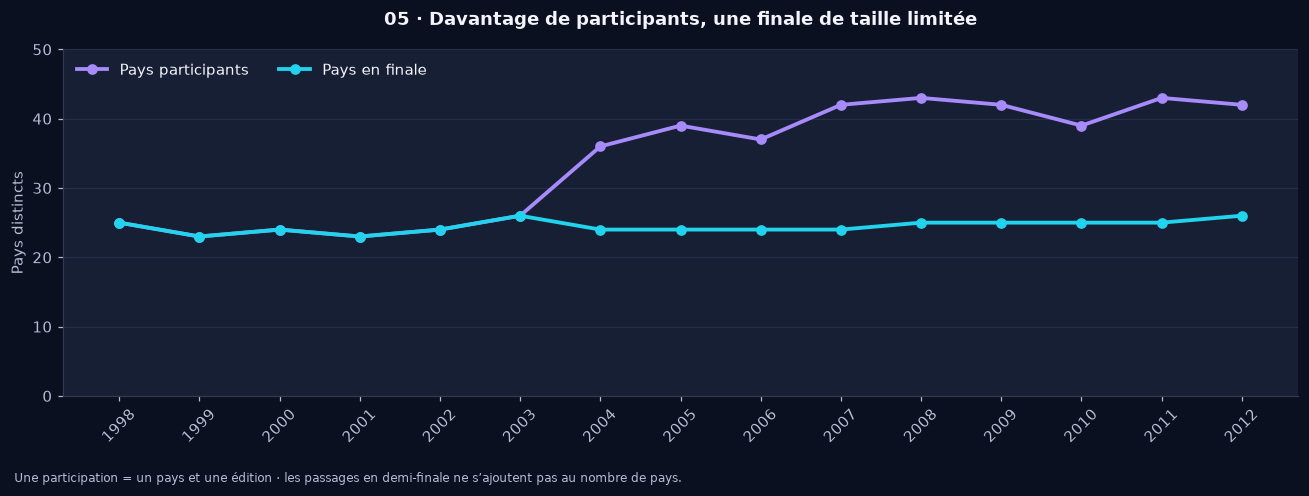

In [25]:
fig,ax=plt.subplots(figsize=(12,4.5))
ax.plot(editions.edition,editions.participations,marker='o',color=C['violet'],lw=2.5,label='Pays participants')
ax.plot(editions.edition,editions.finalistes,marker='o',color=C['cyan'],lw=2.5,label='Pays en finale')
ax.set_xticks(editions.edition);ax.tick_params(axis='x',rotation=45);ax.set_ylim(0,50)
ax.set_ylabel('Pays distincts');ax.set_title('05 · Davantage de participants, une finale de taille limitée')
ax.grid(axis='y',alpha=.6);ax.legend(frameon=False,ncol=2,loc='upper left')
save_figure(fig,'05_participation_editions','Une participation = un pays et une édition · les passages en demi-finale ne s’ajoutent pas au nombre de pays.')

**Le palmarès du périmètre.** Les victoires sont comptées uniquement sur les finales, et toutes les lignes sont affichées.

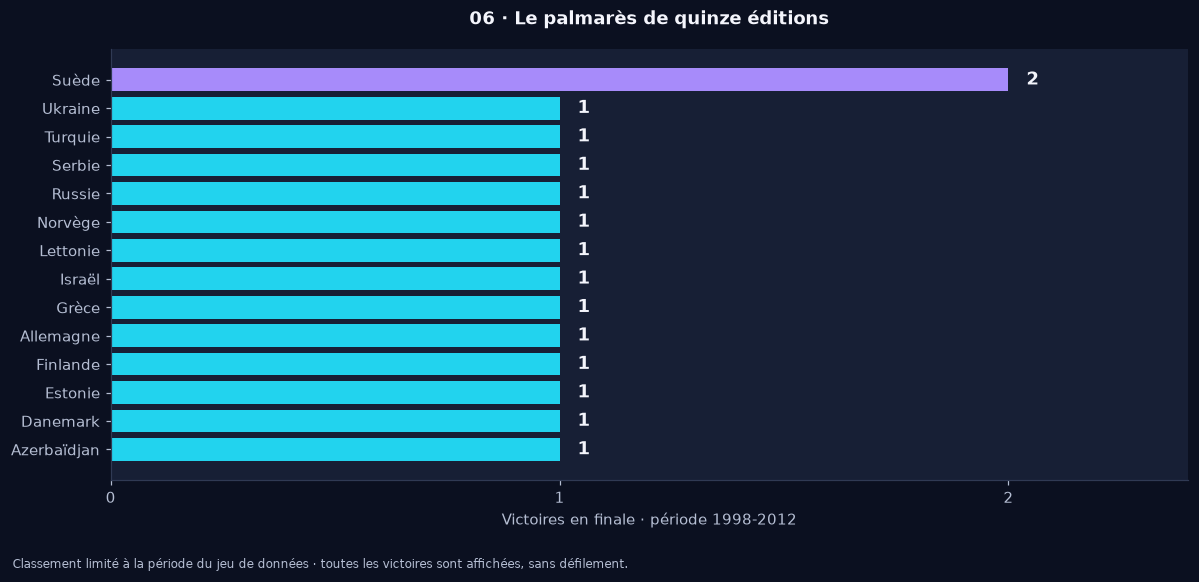

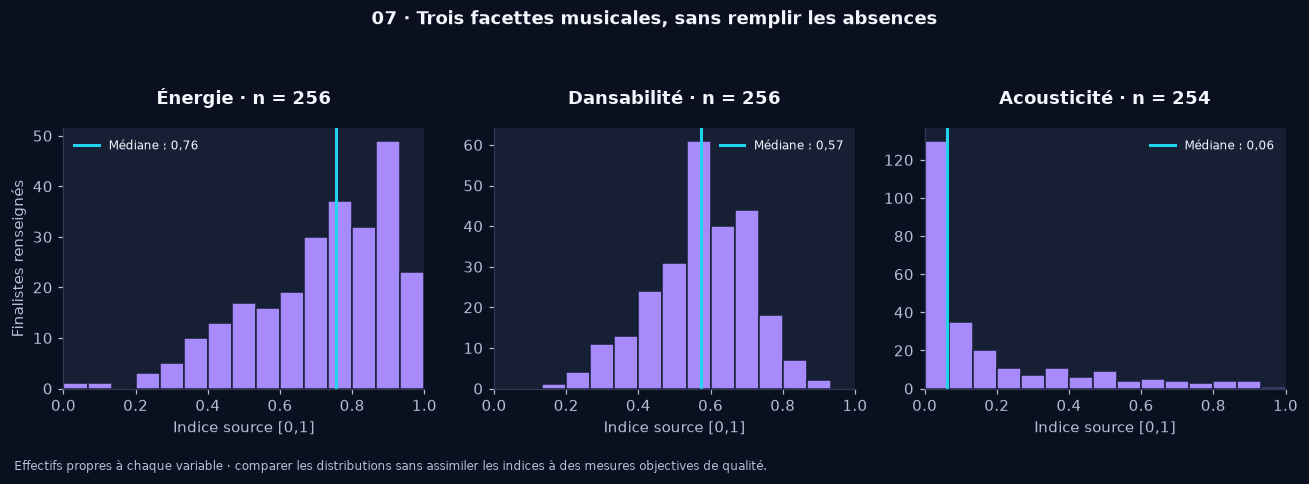

In [26]:
winners=m.loc[m.etape.eq('F')&m.Place.eq(1)].groupby('Country').size().sort_values(kind='stable')
fig,ax=plt.subplots(figsize=(11,5.3))
ax.barh([COUNTRY_FR[x] for x in winners.index],winners,color=[C['violet'] if x==winners.max() else C['cyan'] for x in winners])
for i,value in enumerate(winners):ax.text(value+.04,i,str(value),va='center',fontsize=12,fontweight='bold')
ax.set_xlim(0,winners.max()+.4);ax.set_xticks(range(int(winners.max())+1));ax.set_xlabel('Victoires en finale · période 1998-2012')
ax.set_title('06 · Le palmarès de quinze éditions')
save_figure(fig,'06_palmares','Classement limité à la période du jeu de données · toutes les victoires sont affichées, sans défilement.')
finals=m.loc[m.etape.eq('F')].copy()
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,col in zip(axes,PROFILE):
    obs=finals[col].dropna();ax.hist(obs,bins=np.linspace(0,1,16),color=C['violet'],edgecolor=C['panel'])
    ax.axvline(obs.median(),color=C['cyan'],lw=2,label=f'Médiane : {fr(obs.median(),2)}')
    ax.set_title(f'{LABELS[col]} · n = {len(obs)}');ax.set_xlim(0,1);ax.set_xlabel('Indice source [0,1]');ax.legend(frameon=False,fontsize=8)
axes[0].set_ylabel('Finalistes renseignés')
fig.suptitle('07 · Trois facettes musicales, sans remplir les absences',fontweight='bold',y=1.06)
save_figure(fig,'07_distributions_profils','Effectifs propres à chaque variable · comparer les distributions sans assimiler les indices à des mesures objectives de qualité.')

**Comparer sur une base commune.** Les trois moyennes de chaque groupe utilisent exactement les mêmes chansons.

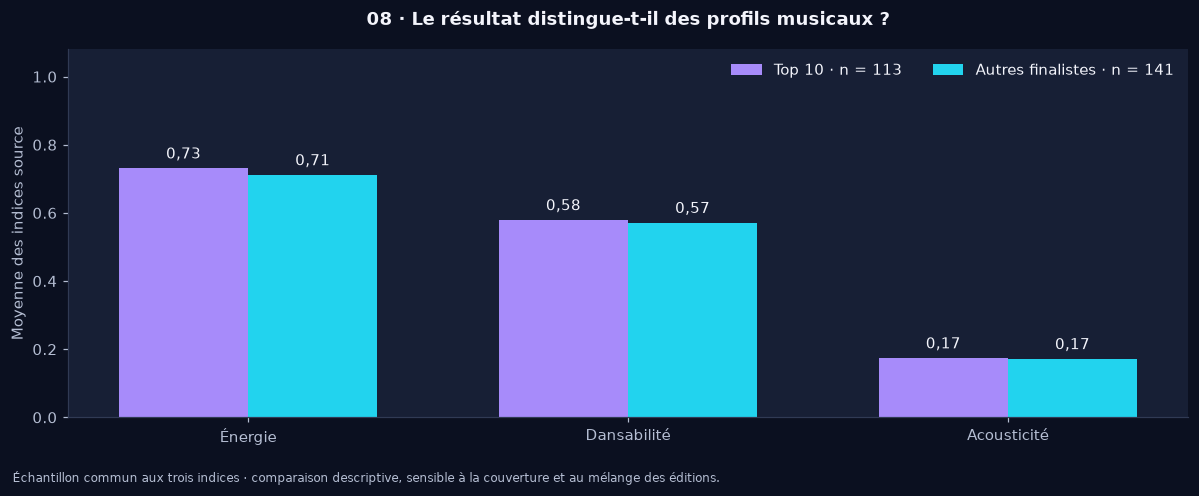

groupe,finalistes,profils_connus,couverture_pct
Autres finalistes,217,141,"64,977"
Top 10,150,113,"75,333"


In [27]:
common=finals.loc[finals.profil_complet].copy()
common['groupe']=np.where(common.Place.le(10),'Top 10','Autres finalistes')
profiles=common.groupby('groupe')[PROFILE].mean().reindex(['Top 10','Autres finalistes'])
counts=common.groupby('groupe').size().reindex(profiles.index)
fig,ax=plt.subplots(figsize=(11,4.5));x=np.arange(len(PROFILE))
for i,(group,color) in enumerate(zip(profiles.index,[C['violet'],C['cyan']])):
    bars=ax.bar(x+(i-.5)*.34,profiles.loc[group],width=.34,color=color,label=f'{group} · n = {int(counts[group])}')
    ax.bar_label(bars,labels=[fr(v,2) for v in profiles.loc[group]],padding=4,color=C['text'])
ax.set_xticks(x,[LABELS[v] for v in PROFILE]);ax.set_ylim(0,1.08);ax.set_ylabel('Moyenne des indices source')
ax.set_title('08 · Le résultat distingue-t-il des profils musicaux ?');ax.legend(frameon=False,ncol=2,loc='upper right')
save_figure(fig,'08_profils_top10','Échantillon commun aux trois indices · comparaison descriptive, sensible à la couverture et au mélange des éditions.')
coverage_groups=finals.assign(groupe=np.where(finals.Place.le(10),'Top 10','Autres finalistes')).groupby('groupe').agg(
    finalistes=('Country','size'),profils_connus=('profil_complet','sum'))
coverage_groups['couverture_pct']=coverage_groups.profils_connus/coverage_groups.finalistes*100
table(coverage_groups.reset_index(),'Le biais de couverture concerne aussi la comparaison des groupes')
lecture(f'La comparaison des profils porte sur {len(common)} finalistes : '+', '.join(f'{g} : {int(counts[g])}' for g in counts.index)+'. Les différences de moyennes ne suffisent pas à expliquer le vote ; les chansons absentes et les effets d’édition peuvent modifier ce portrait.')

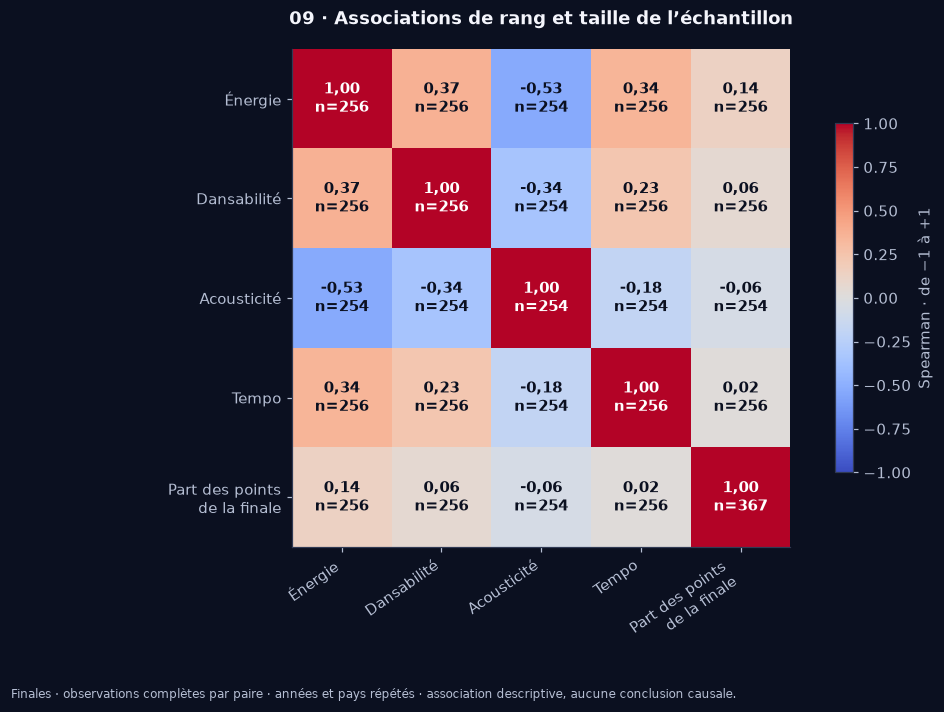

In [28]:
CORR_COLS=PROFILE+['tempo','part_points_etape']
CORR_LABELS=[LABELS.get(c,'Part des points\nde la finale') for c in CORR_COLS]
rho=pd.DataFrame(np.nan,index=CORR_COLS,columns=CORR_COLS)
pair_n=pd.DataFrame(0,index=CORR_COLS,columns=CORR_COLS,dtype=int)
for a in CORR_COLS:
    for b in CORR_COLS:
        pair=finals[[a,b]].dropna() if a!=b else finals[[a]].dropna()
        pair_n.loc[a,b]=len(pair)
        rho.loc[a,b]=1.0 if a==b else spearmanr(pair[a].astype(float),pair[b].astype(float)).statistic
fig,ax=plt.subplots(figsize=(9,6.5))
im=ax.imshow(rho.to_numpy(float),cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(len(CORR_COLS)),CORR_LABELS,rotation=35,ha='right')
ax.set_yticks(range(len(CORR_COLS)),CORR_LABELS)
for i,a in enumerate(CORR_COLS):
    for j,b in enumerate(CORR_COLS):
        ax.text(j,i,f'{fr(rho.loc[a,b],2)}\nn={int(pair_n.loc[a,b])}',ha='center',va='center',color=('#FFFFFF' if abs(rho.loc[a,b])>.65 else '#0B1020'),fontsize=10,fontweight='bold')
ax.set_title('09 · Associations de rang et taille de l’échantillon')
fig.colorbar(im,ax=ax,shrink=.7,label='Spearman · de −1 à +1')
save_figure(fig,'09_correlations_spearman','Finales · observations complètes par paire · années et pays répétés · association descriptive, aucune conclusion causale.')

**Lire une évolution avec sa couverture.** Chaque point précise le nombre de finalistes effectivement renseignés.

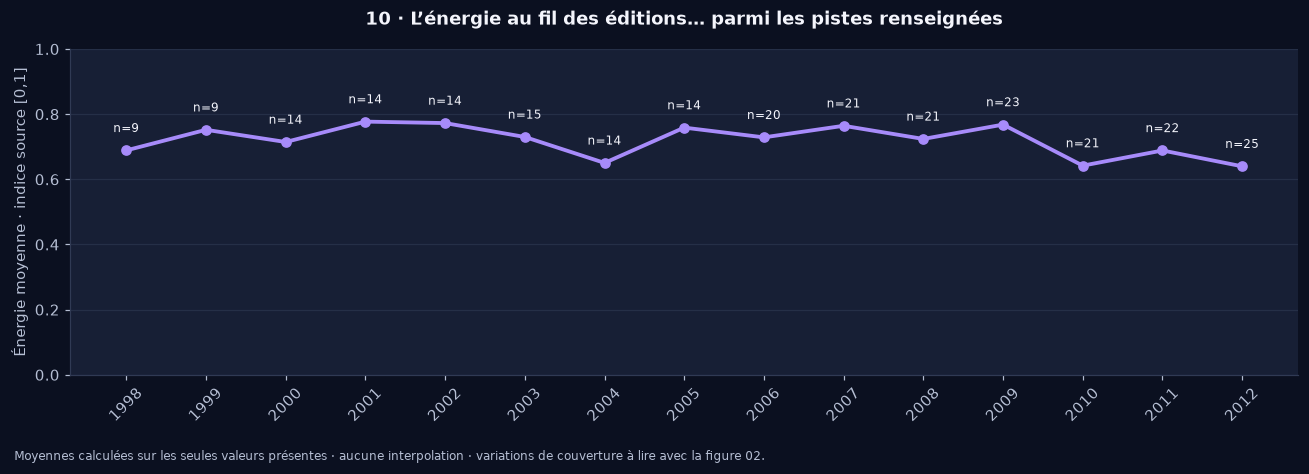

Variable,Spearman / part des points,Finalistes comparés
Énergie,"0,137",256
Dansabilité,"0,062",256
Acousticité,"-0,059",254
Tempo,"0,020",256


In [29]:
energy_year=finals.groupby('Year').energy.agg(['mean','count']).reset_index()
fig,ax=plt.subplots(figsize=(12,4.3))
ax.plot(energy_year.Year,energy_year['mean'],color=C['violet'],marker='o',lw=2.5)
for _,r in energy_year.iterrows():ax.annotate(f'n={int(r["count"])}',(r.Year,r['mean']),xytext=(0,12),textcoords='offset points',ha='center',fontsize=8)
ax.set_xticks(energy_year.Year);ax.tick_params(axis='x',rotation=45);ax.set_ylim(0,1)
ax.set_ylabel('Énergie moyenne · indice source [0,1]');ax.set_title('10 · L’énergie au fil des éditions… parmi les pistes renseignées')
ax.grid(axis='y',alpha=.6)
save_figure(fig,'10_energie_editions','Moyennes calculées sur les seules valeurs présentes · aucune interpolation · variations de couverture à lire avec la figure 02.')
association=[]
for col in PROFILE+['tempo']:
    association.append({'Variable':LABELS[col],'Spearman / part des points':rho.loc[col,'part_points_etape'],
        'Finalistes comparés':pair_n.loc[col,'part_points_etape']})
table(pd.DataFrame(association),'Les associations observées dans ce jeu historique')

<a id="etape-12"></a>
<h2 style="color:#7C3AED;border-bottom:2px solid #DDD6FE;padding-bottom:10px;">12 · Exporter, relire et vérifier la reproduction</h2>


Le classeur `eurovision_clean.xlsx` contient les cinq tables du modèle, les deux feuilles d’audit qui préservent les observations sources, un dictionnaire des champs préparés et une feuille de lecture. Les tables Excel sont filtrables, les en-têtes sont figés et les valeurs manquantes sont écrites comme cellules vides.

Les rapports CSV utilisent UTF-8 avec BOM, une virgule comme séparateur et un point décimal. Ils rendent visibles le journal de transformation, les corrections vérifiées, les rapprochements avant et après, la couverture, les variantes restantes et les alertes textuelles.

Les contrôles ci-dessous vérifient les clés et leurs références, les comptages, les sommes, la préservation des sources et **toutes les valeurs de chaque feuille après relecture Excel**. Le rapport JSON contient les empreintes logiques des tables et du code pour comparer des exécutions, sans confondre contenu des données et métadonnées internes d’un fichier `.xlsx`.

In [30]:
check('Comptages de référence : 15 éditions, 48 pays, 508 participations, 648 passages, 12131 votes',
    [len(core_tables[x]) for x in core_tables]==[15,48,508,648,12131])
for name,df in core_tables.items():
    key={'editions':'edition','pays':'pays_id','participations':'participation_id','resultats_etapes':'resultat_id','votes_finale':'vote_id'}[name]
    check('Clé primaire : '+name,df[key].notna().all() and df[key].is_unique)
check('Passages → participations',resultats.participation_id.isin(participations.participation_id).all())
check('Participations → pays',participations.pays_id.isin(pays.pays_id).all())
check('Participations → éditions',participations.edition.isin(editions.edition).all())
check('Votes → finalistes',votes.participation_id.isin(participations.loc[participations.est_finaliste,'participation_id']).all())
check('Votes → pays donneurs et destinataires',votes[['pays_destinataire_id','pays_donneur_id']].isin(pays.pays_id.tolist()).all().all())
donors_offstage=votes[['edition','pays_donneur_id']].drop_duplicates().copy()
donors_offstage['participation_id']=donors_offstage.edition.astype(str)+'_'+donors_offstage.pays_donneur_id
donors_offstage=donors_offstage.loc[~donors_offstage.participation_id.isin(participations.participation_id)].copy()
donors_offstage['pays']=donors_offstage.pays_donneur_id.map(pays.set_index('pays_id').pays_source)
check('Donneurs sans passage : seule exception documentée en 2006',
    set(zip(donors_offstage.edition,donors_offstage.pays))=={(2006,'Serbia and Montenegro')})
donors_offstage['raison']='Retrait de la scène en 2006 ; maintien du droit de vote confirmé par l’EBU.'
donors_offstage['reference']='https://www.eurovision.com/stories/the-20-year-evolution-of-the-eurovision-semi-finals/'
check('Passages : année et pays conformes à la participation',all(
    (row.participation_id==f'{row.edition}_{row.pays_id}') for row in resultats.itertuples()))
check('Votes : destinataire conforme à la participation',all(
    row.participation_id==f'{row.edition}_{row.pays_destinataire_id}' for row in votes.itertuples()))
check('Somme de la part des points = 1 par étape',np.allclose(resultats.groupby(['edition','etape']).part_points_etape.sum(),1))
check('Nombre de finales : 367',int(participations.est_finaliste.sum())==367)
check('Aucune imputation musicale',all(
    np.array_equal(m[c].isna().to_numpy(),raw[c].map(missing_token).to_numpy()) for c in AUDIO+['Happiness']))
check('Nombre total de passages conservé',int(participations.nombre_passages.sum())==len(raw))
check('Source et copie de travail inchangées',hashes_before=={str(p.relative_to(ROOT)):sha256(p) for p in input_paths})
check('Libellés : alertes résiduelles documentées',text_alerts.empty,
    f'{len(text_alerts)} cellules restent signalées, sans correction spéculative',warning=True)
check('Régions : taxonomie source non documentée, champ exclu des analyses',False,
    '6 variantes de région conservées par étape ; aucune région inventée',warning=True)
check('Song.Quality : formule source inconnue, score exclu des analyses',False,
    '138 variantes conservées par étape ; aucune agrégation utilisée',warning=True)
check('Provenance amont du jeu enrichi renseignée',False,
    'Auteur, licence et version de collecte non documentés dans le classeur local',warning=True)

**Documenter les sorties.** Chaque champ du modèle reçoit une description, un type et son nombre de valeurs nulles.

In [31]:
source_desc=source_dictionary.set_index('Column name').Description.to_dict()
manual_desc={
 'edition':'Année de l’édition, 1998-2012.', 'pays_id':'Clé interne de l’entité historique dans ce périmètre.',
 'pays_source':'Nom de pays harmonisé, entités historiques distinctes.', 'pays_fr':'Libellé français d’affichage, sans fusion historique.',
 'entite_historique':'Vrai pour l’entité Serbie-et-Monténégro, conservée séparément.',
 'participation_id':'Clé pays-édition : année + pays_id.', 'resultat_id':'Clé participation-étape.',
 'vote_id':'Clé participation destinataire-pays donneur ; finale uniquement.',
 'ligne_excel':'Numéro de ligne du classeur source, en-tête = 1.',
 'ligne_representative':'Ligne source retenue : finale si présente, sinon demi-finale ; sans moyenne ni remplissage.',
 'artiste':'Libellé harmonisé ; corrections officielles détaillées dans le journal.',
 'chanson':'Titre harmonisé ; toute version de la source reste dans audit_source.',
 'genre_source':'Catégorie déclarée par la source, jamais inférée.', 'formation_source':'Solo / Group déclarés par la source ; non renseigné = cellule vide.',
 'image_url':'URI data: intégrée à partir du fichier vérifié, inférieure à 32760 caractères ; photo ou remplacement selon image_type.',
 'profil_complet':'Énergie, dansabilité et acousticité toutes renseignées.',
 'duree_atypique':'Hors intervalle de Tukey calculé sur les passages observés ; signalement sans exclusion.',
 'est_finaliste':'Au moins un passage observé en finale.', 'nombre_passages':'Nombre de passages observés pour cette participation.',
 'etape':'F = finale ; SF1 / SF2 = demi-finale 1 / 2.', 'est_finale':'Vrai si etape = F.',
 'identifiant_source':'Sr.No d’origine converti en entier nullable ; une absence est conservée.',
 'place':'Rang de l’étape après corrections vérifiées ; pas de recalcul automatique des ex æquo.',
 'points':'Points de l’étape ou du vote selon la table, après corrections vérifiées.',
 'points_source':'Points de l’étape avant correction, conservés pour audit.', 'place_source':'Place avant correction, conservée pour audit.',
 'correction_resultat':'Points ou place différents de la source à la suite d’une correction vérifiée.',
 'normalized_points_source':'Ratio de la source, non écrasé ; dénominateur exact non entièrement réconcilié.',
 'part_points_etape':'Points corrigés / somme des points corrigés de la même édition et de la même étape.',
 'song_quality_source':'Score estimé opaque de la source, peut varier entre étapes ; exclu des conclusions centrales.',
 'region_source':'Regroupement de la source, parfois variable entre étapes ; pas un continent officiel.',
 'chanson_en_anglais_source':'Drapeau source, maintenu par étape en raison d’une variante non résolue.',
 'pays_hote_source':'Indication Home / Away de la source ; non complétée à partir de connaissances externes.',
 'region_hote_source':'Home / Away selon le regroupement régional de la source.',
 'happiness_source':'Moyenne lexicale labMT selon le dictionnaire ; couverture et langue limitent l’interprétation.',
 'pays_destinataire_id':'Pays finaliste recevant le vote.', 'pays_donneur_id':'Pays votant ; dimension de rôle distincte conseillée dans Power BI.',
 'score_source':'Valeur du vote avant correction.', 'vote_corrige':'Vrai si une référence officielle justifie la correction du vote.',
 'participations':'Nombre de pays distincts inscrits dans les données de cette édition.',
 'finalistes':'Nombre de pays observés en finale.', 'profils_musicaux_connus':'Participations dont les trois indices du profil sont connus, toutes étapes.',
 'passages':'Total des passages de l’édition ; différent du nombre de participations.',
 'nombre_demi_finales':'Nombre de demi-finales distinctes observées dans l’édition.',
 'total_points_finale':'Somme des points corrigés des finalistes de l’édition.',
 'nombre_donneurs_finale':'Nombre de pays donneurs de points en finale.',
 'profils_finalistes_connus':'Finalistes avec les trois indices musicaux renseignés.',
 'couverture_profil_finale':'Profils finalistes connus / nombre de finalistes, ratio [0,1].'}
manual_desc.update({
 'chanson_en_anglais_reference':'Indicateur source de langue pour la ligne représentative (finale si présente, sinon demi-finale) ; aucune propagation aux autres étapes.',
 'image_url_source':'Ancienne URL de la source, conservée pour audit ; peut être absente ou associée au mauvais sujet.',
 'image_url_distante':'URL de téléchargement de la photographie documentée ; vide pour les pictogrammes créés dans le projet.',
 'image_type':'photographie / photographie_collaboration / image_prestation (miniature vidéo, droits réservés) ; visuel_remplacement réservé aux absences explicites, aucune dans le catalogue actuel.',
 'image_sujet':'Sujet indiqué par la référence : artiste, membre de collaboration ou pictogramme sans personne.',
 'image_fichier':'Chemin relatif du fichier vérifié, portable avec le dépôt.',
 'image_source':'Page de description du fichier et de ses droits.',
 'image_auteur':'Crédit Commons ou chaîne vidéo source ; une chaîne n’est pas présumée auteur de la miniature.',
 'image_licence':'Licence déclarée par Commons ou mention Droits réservés pour les miniatures vidéo ; aucune licence du projet attribuée aux images tierces.',
 'image_licence_url':'Lien vers les conditions de la licence de l’image.',
 'image_sha256':'Empreinte du fichier exact utilisé pour l’affichage.',
 'image_date_verification':'Date de la collecte et de la vérification technique du visuel.'})
def describe(col):
    if col in manual_desc:return manual_desc[col]
    if col.endswith('_disponible'):return 'Vrai si '+col.removesuffix('_disponible')+' est renseigné ; faux ≠ zéro.'
    if col in AUDIO:
        domain='Indice [0,1]. ' if col in BOUNDED else ''
        if col in ['duration','loudness','tempo']:domain+='Unité non précisée dans le dictionnaire local. '
        return domain+source_desc.get(col,'Caractéristique source.')+' Valeur observée, sans imputation.'
    raise KeyError('Description manquante : '+col)
dictionary_rows=[]
for name,df in core_tables.items():
    for col in df:
        dictionary_rows.append(dict(table=name,variable=col,type_python=str(df[col].dtype),
            valeurs_nulles=int(df[col].isna().sum()),description=describe(col)))
output_dictionary=pd.DataFrame(dictionary_rows)
# Dictionnaire des huit tables réellement importées dans Power BI.
manual_desc.update({'libelle_participation':'Artiste / collaboration, pays français et année ; libellé de sélection, la clé reste participation_id.', 'libelle_chanson':'Chanson, année et pays ; identifiant lisible des points du nuage.', 'langue_reference':'Libellé français du code source de la ligne représentative ; nul si absent.', 'libelle_etape':'Nom français de l’étape source.', 'ordre_etape':'Ordre de présentation : demi-finale 1, demi-finale 2, finale ; ce ne sont pas de nouvelles observations.', 'groupe_classement':'Top 10 ou autres finalistes, défini seulement en finale ; nul pour les demi-finales.'})
model_dictionary=pd.DataFrame([dict(table=name,variable=col,type_python=str(df[col].dtype),valeurs_nulles=int(df[col].isna().sum()),description=describe(col)) for name,df in model_tables.items() for col in df])
check('Constellation : dictionnaire complet',len(model_dictionary)==sum(len(df.columns) for df in model_tables.values()) and model_dictionary.description.notna().all())


**Créer le classeur.** Les tables métier, le dictionnaire et les deux audits sont exportés ensemble, avec une feuille de conventions.

In [32]:
notes=pd.DataFrame([
 ['Périmètre','1998-2012 ; demi-finales et finales présentes ; aucune donnée postérieure ajoutée.'],
 ['Sources','Classeur local eurovision_1998 to 2012.xlsx ; attribution amont et licence non documentées.'],
 ['Absences','Cellules vides ; aucun NA textuel dans les colonnes numériques ; aucune imputation musicale.'],
 ['Granularité','Participations ≠ passages ; votes de finale distincts des résultats agrégés.'],
 ['Corrections','Journal CSV et corrections officielles CSV ; références vérifiées le '+VERIFY_DATE+'.'],
 ['Normalisation','part_points_etape : points corrigés / total corrigé édition-étape ; ratio source conservé.'],
 ['Audit','audit_source et audit_votes contiennent les valeurs originales, y compris les codes NA.'],
 ['Limites','Libellés suspects résiduels, enregistrement audio et unités non documentés ; pas de lien causal démontré.'],
 ['Power BI','Ce classeur conserve les cinq tables de préparation et les audits. Le modèle Power BI importe les huit tables de eurovision_constellation.xlsx ; les images data: sont dans dim_participations.'],
 ['Régénération','Redémarrer le noyau puis tout exécuter dans traitement_donnees.ipynb.']
],columns=['Sujet','Convention'])
excel_tables={**core_tables,'dictionnaire':output_dictionary,'lecture':notes,
    'audit_source':source_values,'audit_votes':source_vote_values}
workbook_path=PROCESSED/'eurovision_clean.xlsx'
with pd.ExcelWriter(workbook_path,engine='openpyxl') as writer:
    for number,(name,df) in enumerate(excel_tables.items(),start=1):
        df.to_excel(writer,sheet_name=name,index=False,na_rep='')
        ws=writer.sheets[name];ws.freeze_panes='A2';ws.sheet_view.showGridLines=False
        tab=Table(displayName=f'Eurovision_{number}',ref=ws.dimensions)
        tab.tableStyleInfo=TableStyleInfo(name='TableStyleMedium2',showRowStripes=True)
        ws.add_table(tab)
        for cell in ws[1]:
            cell.font=Font(color='FFFFFF',bold=True);cell.fill=PatternFill('solid',fgColor='171F35')
            cell.alignment=Alignment(vertical='center')
        ws.row_dimensions[1].height=30
        for i,col in enumerate(df.columns,start=1):
            sampled=df[col].head(150).astype(object).where(df[col].head(150).notna(), '').astype(str).map(len)
            width=max(len(col)+2,int(sampled.quantile(.9))+2 if len(sampled) else 12)
            ws.column_dimensions[ws.cell(1,i).column_letter].width=min(52,max(12,width))
            if col=='image_url':ws.column_dimensions[ws.cell(1,i).column_letter].hidden=True
            if col=='part_points_etape' or col=='couverture_profil_finale':
                for cell in list(ws.columns)[i-1][1:]:cell.number_format='0.0%'

**Relire toutes les feuilles.** Les valeurs numériques sont comparées avec une tolérance de 10⁻¹² ; les textes et la structure sont également vérifiés.

In [33]:
# Comparer les valeurs, pas les métadonnées ZIP/Excel.
read_back=pd.read_excel(workbook_path,sheet_name=None,keep_default_na=False)
check('Relecture : toutes les feuilles présentes',list(read_back)==list(excel_tables))
for name,expected in excel_tables.items():
    actual=read_back[name]
    check('Relecture : dimensions et colonnes / '+name,actual.shape==expected.shape and list(actual)==list(expected))
    for col in expected:
        if pd.api.types.is_numeric_dtype(expected[col].dtype):
            a=pd.to_numeric(actual[col].replace('',np.nan),errors='raise').to_numpy(dtype=float,na_value=np.nan)
            b=expected[col].to_numpy(dtype=float,na_value=np.nan)
            np.testing.assert_allclose(a,b,rtol=1e-12,atol=1e-12,equal_nan=True,err_msg=f'{name}.{col}')
        else:
            # Les audits contiennent des nombres mêlés aux codes textuels NA.
            # Comparer leurs nombres avec la même tolérance, leurs tokens exactement.
            numeric_cells=expected[col].map(lambda x:isinstance(x,(int,float,np.number)) and not isinstance(x,(bool,np.bool_)))
            if numeric_cells.any():
                a=pd.to_numeric(actual.loc[numeric_cells,col],errors='raise').to_numpy(float)
                b=pd.to_numeric(expected.loc[numeric_cells,col],errors='raise').to_numpy(float)
                np.testing.assert_allclose(a,b,rtol=1e-12,atol=1e-12,equal_nan=True,err_msg=f'{name}.{col}')
            a=actual.loc[~numeric_cells,col].fillna('').astype(str).tolist()
            b=expected.loc[~numeric_cells,col].fillna('').astype(str).tolist()
            if a!=b:raise AssertionError(f'Relecture texte : {name}.{col}')
    check('Relecture : toutes les valeurs / '+name,True)

**Constituer les preuves de reproduction.** Les empreintes logiques portent sur le contenu des tables, indépendamment des métadonnées Excel.

In [34]:
# Empreinte logique stable : inclut ordre des colonnes, lignes et valeurs, indépendamment du conteneur Excel.
def logical_hash(df):
    payload=df.to_json(orient='split',index=False,force_ascii=False,double_precision=15)
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()
manifest={name:{'lignes':len(df),'colonnes':len(df.columns),'sha256_logique':logical_hash(df),
    'types':{c:str(df[c].dtype) for c in df}} for name,df in excel_tables.items()}
reconciliation=recon_before.rename(columns={'Points':'points_avant','Place':'place_avant','somme_votes':'votes_avant','ecart':'ecart_avant'}).drop(columns='_merge').merge(
    recon_after.rename(columns={'Points':'points_apres','Place':'place_apres','somme_votes':'votes_apres','ecart':'ecart_apres'}).drop(columns='_merge'),
    on=['Year','Country'],validate='one_to_one').rename(columns={'Year':'edition','Country':'pays'})
reports={
 'revue_libelles':revue_libelles, 'revue_variantes':revue_variantes,
 'images_droits_reserves':images_droits_reserves, 'verification_collaborations':verification_collaborations,
 'diagnostic_qualite':pd.DataFrame(controls), 'couverture_images':image_coverage, 'credits_images':credits_images, 'journal_transformations':pd.DataFrame(journal),
 'donneurs_sans_passage':donors_offstage,
 'corrections_officielles':corrections_officielles,'references_verifiees':references,
 'rapprochement_votes':reconciliation,'couverture_finales':coverage,
 'absences_variables':missing_report,'types_prepares':type_report,'dictionnaire_sorties':output_dictionary, 'dictionnaire_constellation':model_dictionary,
 'normalisation_points':normalization,'anomalies_texte':text_alerts,
 'variantes_etapes_avant':variants_before,'variantes_etapes_apres':variants_after,
 'durees_atypiques':extremes,'associations_spearman':pd.DataFrame(association),
 'effectifs_correlations':pair_n.rename_axis('variable').reset_index(),
 'correlations_spearman':rho.rename_axis('variable').reset_index()}
for name,df in reports.items():
    df.to_csv(REPORTS/f'{name}.csv',index=False,encoding='utf-8-sig',lineterminator='\n')
check('Sources toujours inchangées après export',hashes_before=={str(p.relative_to(ROOT)):sha256(p) for p in input_paths})
# Le dernier contrôle doit également figurer dans le CSV de diagnostic.
reports['diagnostic_qualite']=pd.DataFrame(controls)
reports['diagnostic_qualite'].to_csv(REPORTS/'diagnostic_qualite.csv',index=False,encoding='utf-8-sig',lineterminator='\n')
code_hash=hashlib.sha256('\n\n'.join(''.join(c['source']) for c in json.loads((ROOT/'traitement_donnees.ipynb').read_text(encoding='utf-8'))['cells'] if c['cell_type']=='code').encode('utf-8')).hexdigest()
report_hashes={str((REPORTS/f'{name}.csv').relative_to(ROOT)):sha256(REPORTS/f'{name}.csv') for name in reports}
report_hashes.update({str(p.relative_to(ROOT)):sha256(p) for p in figure_paths})
report_hashes[str(gallery_path.relative_to(ROOT))]=sha256(gallery_path)
verification={
 'schema_version':1,'statut':'contrôles bloquants et relecture Excel validés',
 'date_verification_references':VERIFY_DATE,'versions':versions,'sources_sha256':hashes_before,
 'code_notebook_sha256':code_hash,'tables':manifest,'sorties_sha256':report_hashes,
 'controles':{'ok':sum(x['statut']=='OK' for x in controls),'avertissements':sum(x['statut']=='À examiner' for x in controls),
              'echecs':sum(x['statut']=='ÉCHEC' for x in controls)},
 'images':{'visuels':len(image_catalogue),'images_reelles':int(image_catalogue.image_type.ne('visuel_remplacement').sum()),'photographies_wikimedia':int(image_catalogue.image_type.str.startswith('photographie').sum()),'miniatures_prestation_droits_reserves':len(images_droits_reserves),'collaborations_revues':len(verification_collaborations),'remplacements':int(image_catalogue.image_type.eq('visuel_remplacement').sum()),'sha256':image_hashes},
 'imputations_musicales':0,'revue_libelles':{'cellules_revues':len(revue_libelles),'cellules_corrigees':int(revue_libelles.action.eq('Corrigé').sum()),'cellules_validees_sans_modification':int(revue_libelles.action.ne('Corrigé').sum()),'alertes_restantes':len(text_alerts)},'variantes_revues':len(revue_variantes),'ecarts_votes_avant':int(recon_before.ecart.ne(0).sum()),
 'ecarts_votes_apres':int(recon_after.ecart.ne(0).sum()),'corrections_numeriques_verifiees':len(corrections),
 'figures':len(figure_paths),'images_powerbi_sha256_logique':logical_hash(images_powerbi),
 'verification_isolee':'Un second noyau et une copie isolée sont nécessaires pour vérifier indépendamment ces empreintes.'}
(REPORTS/'verification_reproduction.json').write_text(json.dumps(verification,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
table(pd.DataFrame(controls).groupby('statut',sort=False).size().rename('Nombre').reset_index(),'Bilan des contrôles')
table(summary,'Tables exportées')
lecture(f'{len(core_tables)} tables métier, {len(figure_paths)} figures et un journal de {len(journal)} transformations sont exportés. Aucun fichier source ni fichier Power BI n’a été écrit. Les alertes restent disponibles dans les rapports pour la revue collaborative.')
model_manifest={name:{'lignes':len(df),'colonnes':len(df.columns),'sha256_logique':logical_hash(df),'types':{col:str(df[col].dtype) for col in df}} for name,df in model_tables.items()}
model_proof={'schema_version':1,'classeur':'data/processed/eurovision_constellation.xlsx','tables':model_manifest,'relations':[{'fait':f,'cle_etrangere':fk,'dimension':d,'cle_primaire':pk,'cardinalite':'plusieurs vers un','filtrage':'dimension vers fait'} for f,fk,d,pk in model_edges],'imputations_musicales':0,'code_notebook_sha256':code_hash,'source_sha256':hashes_before,'relecture_excel':'toutes cellules validées ; tolérance numérique 1e-12'}
(REPORTS/'verification_constellation_donnees.json').write_text(json.dumps(model_proof,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')


statut,Nombre
OK,185
À examiner,3


Table,Lignes,Colonnes
editions,15,10
pays,48,4
participations,508,51
resultats_etapes,648,20
votes_finale,12 131,9


8201

<div style="background:#0B1020;border-left:5px solid #22D3EE;padding:22px;border-radius:10px;color:#F4F5FC;">
<h3 style="color:#22D3EE;margin-top:0;">Ce que l’on peut désormais montrer</h3>
<p>Une participation clairement définie, un palmarès sur quinze éditions, des résultats de finale cohérents avec les votes détaillés, et des profils musicaux accompagnés de leur couverture.</p>
</div>

**Ce qui reste à examiner ensemble.** Les 135 cellules de libellés signalées ont été revues. Les six variantes de région et les 138 variantes de Song.Quality restent conservées par étape et exclues des analyses ; la langue de la prestation peut varier entre demi-finale et finale. L’identité des enregistrements audio, certaines unités et la formule complète de `Song.Quality` ne sont pas documentées. La provenance amont et les droits du jeu enrichi devront être identifiés avant de présenter ce jeu comme une source officiellement licenciée. L’analyse conserve ces limites au lieu de les effacer.

**Livrables**

- [Revue des libellés](reports/revue_libelles.csv) · [décisions sur les variantes](reports/revue_variantes.csv).

- [Galerie des participants](docs/galerie_participants.html) · [crédits des images](reports/credits_images.csv) · [revue des collaborations](reports/verification_collaborations.csv).
- [Miniatures vidéo dont les droits sont à vérifier](reports/images_droits_reserves.csv).
- [Images intégrées pour Power BI](data/processed/eurovision_images_powerbi.xlsx).

- [Classeur préparé](data/processed/eurovision_clean.xlsx) · cinq tables et feuilles d’audit.
- [Diagnostic qualité](reports/diagnostic_qualite.csv) · [journal des transformations](reports/journal_transformations.csv).
- [Corrections officielles](reports/corrections_officielles.csv) · [rapprochement des votes](reports/rapprochement_votes.csv).
- [Dictionnaire des sorties](reports/dictionnaire_sorties.csv) · [couverture des finales](reports/couverture_finales.csv).
- [Vérification de reproduction](reports/verification_reproduction.json) · [figures calculées](assets/analysis/).

**Raccordement Power BI validé :** les cinq tables métier alimentent le projet `.pbip`. Les dimensions édition et pays filtrent les participations, puis les résultats et les votes ; les pays donneurs de votes ont un rôle distinct. Les mesures musicales utilisent les valeurs observées des finalistes et affichent les effectifs documentés.

**Références.** Les liens officiels et leur date de vérification sont détaillés à l’étape 9 et dans [references_verifiees.csv](reports/references_verifiees.csv). Le dictionnaire de la source reste accessible à l’étape 3. Les bibliothèques servent uniquement au calcul et à la présentation ; aucune ressource web n’est appelée pendant l’exécution.